# 2_phyloseq

## 10.17.26 | tidy metadata

### Setting up R/phyloseq with conda environment in unity

Add phyloseq to `dada2-env` in terminal
```
conda activate dada2-env
conda install -c bionconda bioconda-phyloseq
```

### Metadata tidying

In [ ]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(tidyverse)
})

In [ ]:
# Read 16S processing tracker csv
meta16S <- read.csv("/project/pi_sarah_gignouxwolfsohn_uml_edu/jade/ORCC_16S/metadata/16S_tracker.csv")
dim(meta16S)
head(meta16S)

In [ ]:
# Tidy data
meta16S <- meta16S %>% 
                mutate(Original_order = NULL) %>%
                # Un-concatenate sample name
                separate(Sample_name,  into = c("Year", "Phase_1_treat", "Phase_2_treat", "Tag"), sep = "_", remove = FALSE) %>%
                # Add tissue type to sample name to match ASV table
                mutate(Sample_name = paste0(Sample_name, sep = "_", Tissue)) %>%
                # Separate the treatment and replicate into two columns
                extract(Phase_1_treat, into = c("Phase_1_treat", "Phase_1_rep"), regex = "([A-Za-z]+)([0-9]+)") %>%
                extract(Phase_2_treat, into = c("Phase_2_treat", "Phase_2_rep"), regex = "([A-Za-z]+)([0-9]+)") %>%
                # Add column for treatment combination
                mutate(Combined_treat = paste0(Phase_1_treat, Phase_2_treat)) %>%
                mutate(Combined_treat = gsub("[^A-Z]", "", Combined_treat)) %>%
                relocate(Combined_treat, .after = Year) %>%
                # Make the treatment replicate an integer rather than a string
                mutate(Phase_1_rep = as.integer(Phase_1_rep)) %>%
                mutate(Phase_2_rep = as.integer(Phase_2_rep)) %>%
                # Rename some columns
                rename(Date = X16S_date) %>%
                rename(Adapters = X16S_adapters) %>%
                # Format dates
                mutate(Date = as.Date(Date, format = "%m/%d/%y")) %>%
                mutate(Index_date = as.Date(Index_date, format = "%m/%d/%y"))
head(meta16S)

In [ ]:
# Check warning message
meta16S[239:247,]
meta16S[280:283,]
# Missing pieces are control samples

In [ ]:
# Remove empty rows 282, 283
meta16S <- meta16S[-282:-283,]
tail(meta16S)

In [ ]:
# Save tided csv
write.csv(meta16S, "/project/pi_sarah_gignouxwolfsohn_uml_edu/jade/ORCC_16S/metadata/metadata_samples.csv", row.names=FALSE)

## 10.18.26 | phyloseq object using decipher taxonomy

In [ ]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(tidyverse)
})

In [ ]:
# Read ASV table
asvTable <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ASV_nochim_2.rds")

# Read taxonomy table
taxaDecipher <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/decipher_taxa_sp.rds")

# Read tidied metadata
sampleMetadata <- read.csv("/project/pi_sarah_gignouxwolfsohn_uml_edu/jade/ORCC_16S/metadata/metadata_samples.csv", row.names=1)

In [ ]:
# Check that row names are identical
head(asvTable)
head(sampleMetadata)

In [ ]:
# Rearrange metadata sample order to match ASV table sample order
sampleMetadata <- sampleMetadata[match(rownames(asvTable), rownames(sampleMetadata)), ]
head(asvTable)
head(sampleMetadata)

In [ ]:
# Create phyloseq object
ps <- phyloseq(otu_table(asvTable, taxa_are_rows = FALSE),
                     sample_data(sampleMetadata),
                     tax_table(taxaDecipher))
ps

In [ ]:
# Extract ASV sequences
dna <- Biostrings::DNAStringSet(taxa_names(ps))
names(dna) <- taxa_names(ps)

# Create reference sequence component of phyloseq object to store the raw ASVs
ps <- merge_phyloseq(ps, dna)

# Rename ASVs numerically
taxa_names(ps) <- paste0("ASV", seq(ntaxa(ps)))
ps

In [ ]:
# Save phyloseq object
saveRDS(ps, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps.rds")

## 10.20.26 | clean phyloseq object

Continue work with the phyloseq object created 10.18.26 using the decipher taxonomic assignment tool

In [38]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(tidyverse)
})

In [26]:
# Read in phyloseq object
ps <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps.rds")

In [18]:
# Remove samples with less than 10k reads
ps_10k <- prune_samples(sample_sums(ps) >= 10000, ps)

# Compare phyloseq objects
ps
ps_10k

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 145375 taxa and 281 samples ]
sample_data() Sample Data:       [ 281 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 145375 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 145375 reference sequences ]

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 145375 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 145375 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 145375 reference sequences ]

In [19]:
# Explore which samples were lost
low_samples <- sample_sums(ps) < 10000
sample_names(ps)[low_samples]

[1] "2024_Both01_Null_O03_gill"   "2024_Both04_Null_O32_gill"  
[3] "2024_Both05_Both06_O69_gill" "2024_Cont03_Null_W21_gill"  
[5] "2024_Cont04_Cont06_W67_gill" "2024_Warm01_Hyp05_G49_gill" 
[7] "Pooled_negative_rack3_2_NA"

Samples removed due to <10,000 reads:
- Phase 1 - B1O3_gill, B4O32_gill, C3W21_gill  
- Phase 2 - B5B6O69_gill, C4C6W67_gill, W1J5G49_gill  
- Negative - Pooled negative rack 3_2

In [60]:
# Keep just bacteria
ps_bacteria <- subset_taxa(ps_10k, domain == "Bacteria")
ps_bacteria

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 66795 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 66795 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 66795 reference sequences ]

In [61]:
# Remove taxa that are no longer represented in phyloseq object
ps_prune <- prune_taxa(taxa_sums(ps_bacteria) > 0, ps_bacteria)
ps_prune

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 66218 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 66218 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 66218 reference sequences ]

In [22]:
# Convert raw counts to relative abundance counts per million
ps_norm = transform_sample_counts(ps_prune, function(x) 1E6 * x / sum(x))

In [26]:
# Save phyloseq object
saveRDS(ps_norm, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps_norm.rds")

**Cleaned and pruned phyloseq object to use going forward will be `ps_norm`**

## 10.26.26 | explore the data

In [50]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(tidyverse)
    library(data.table)
})
    
options(repr.plot.width=15, repr.plot.height=8)

### Looking at raw data pre-cleaning

In [2]:
ps <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps.rds")

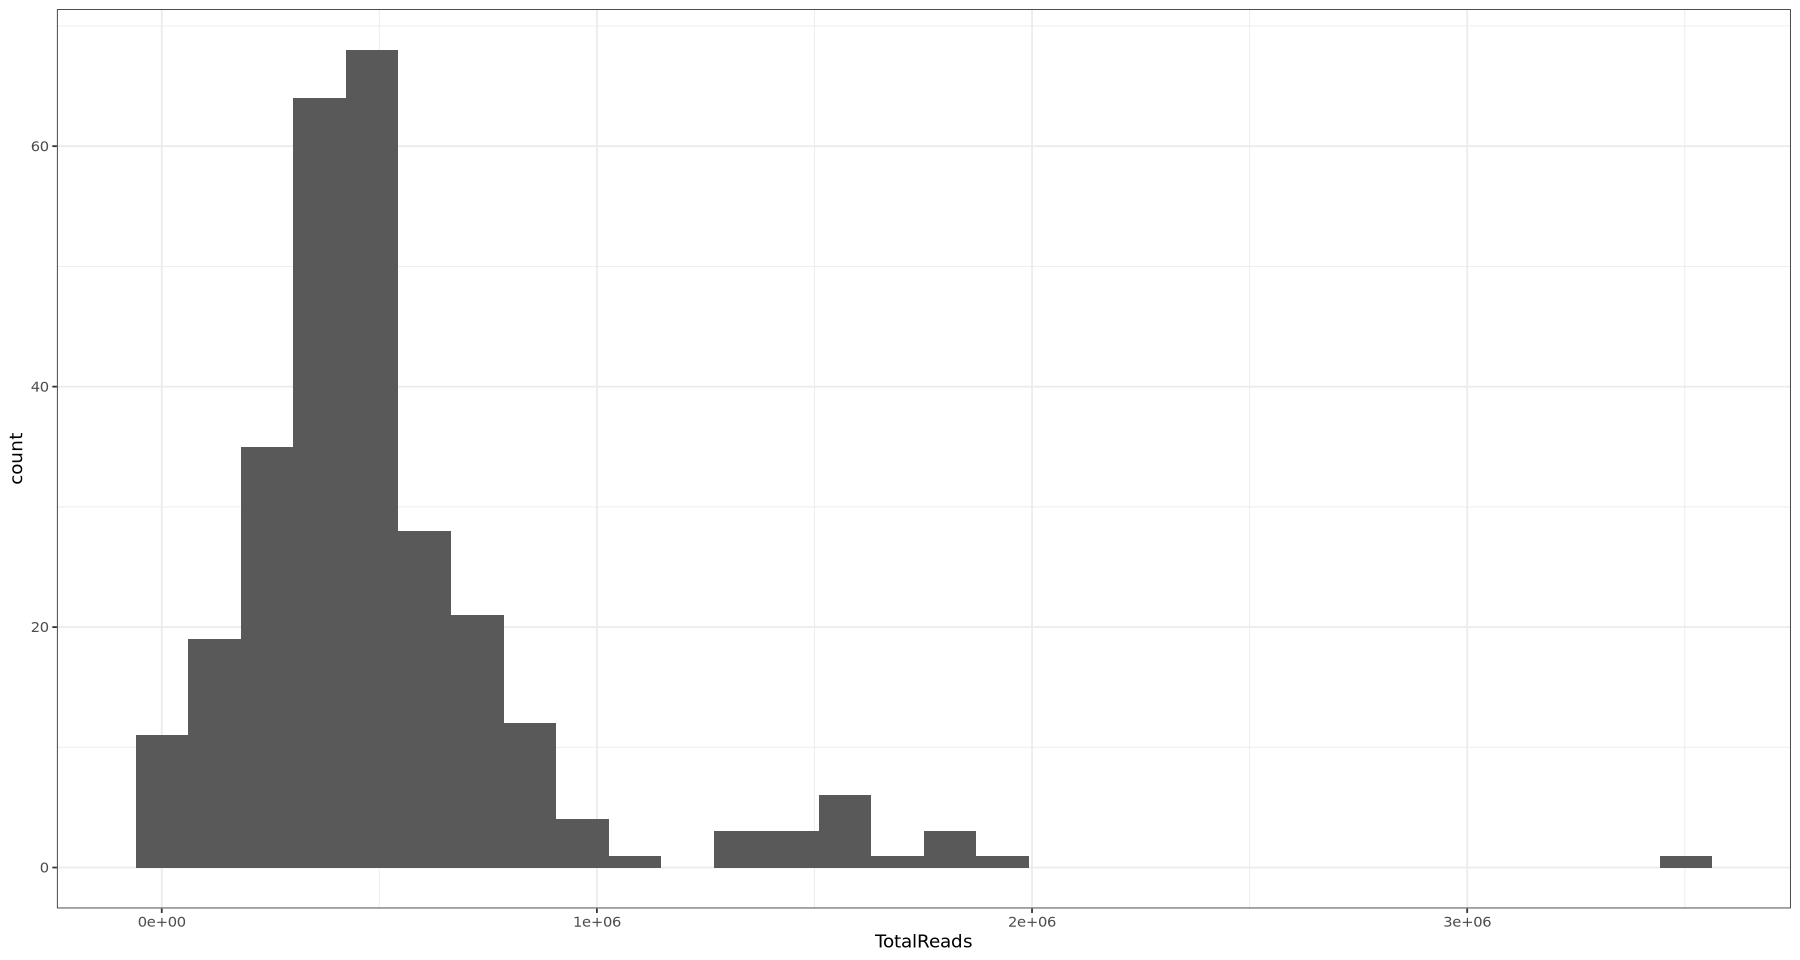

In [13]:
# Check read count of all samples
readcount = data.table(as(sample_data(ps), "data.frame"),
                 TotalReads = sample_sums(ps), 
                 keep.rownames = TRUE)
ggplot(readcount, aes(TotalReads)) + 
    geom_histogram(bins = 30) + 
    theme_bw()

1. How many reads do the negatives have and what are they?
2. What sample has so many reads?
3. We know some 7 samples have < 10,000 reads but what reads do they have?

### Investigate negatives

In [3]:
# Subset ps to only include negatives
ps_neg <- prune_samples(
  grepl("negative", sample_names(ps), ignore.case = TRUE), ps)
ps_neg

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 145375 taxa and 6 samples ]
sample_data() Sample Data:       [ 6 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 145375 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 145375 reference sequences ]

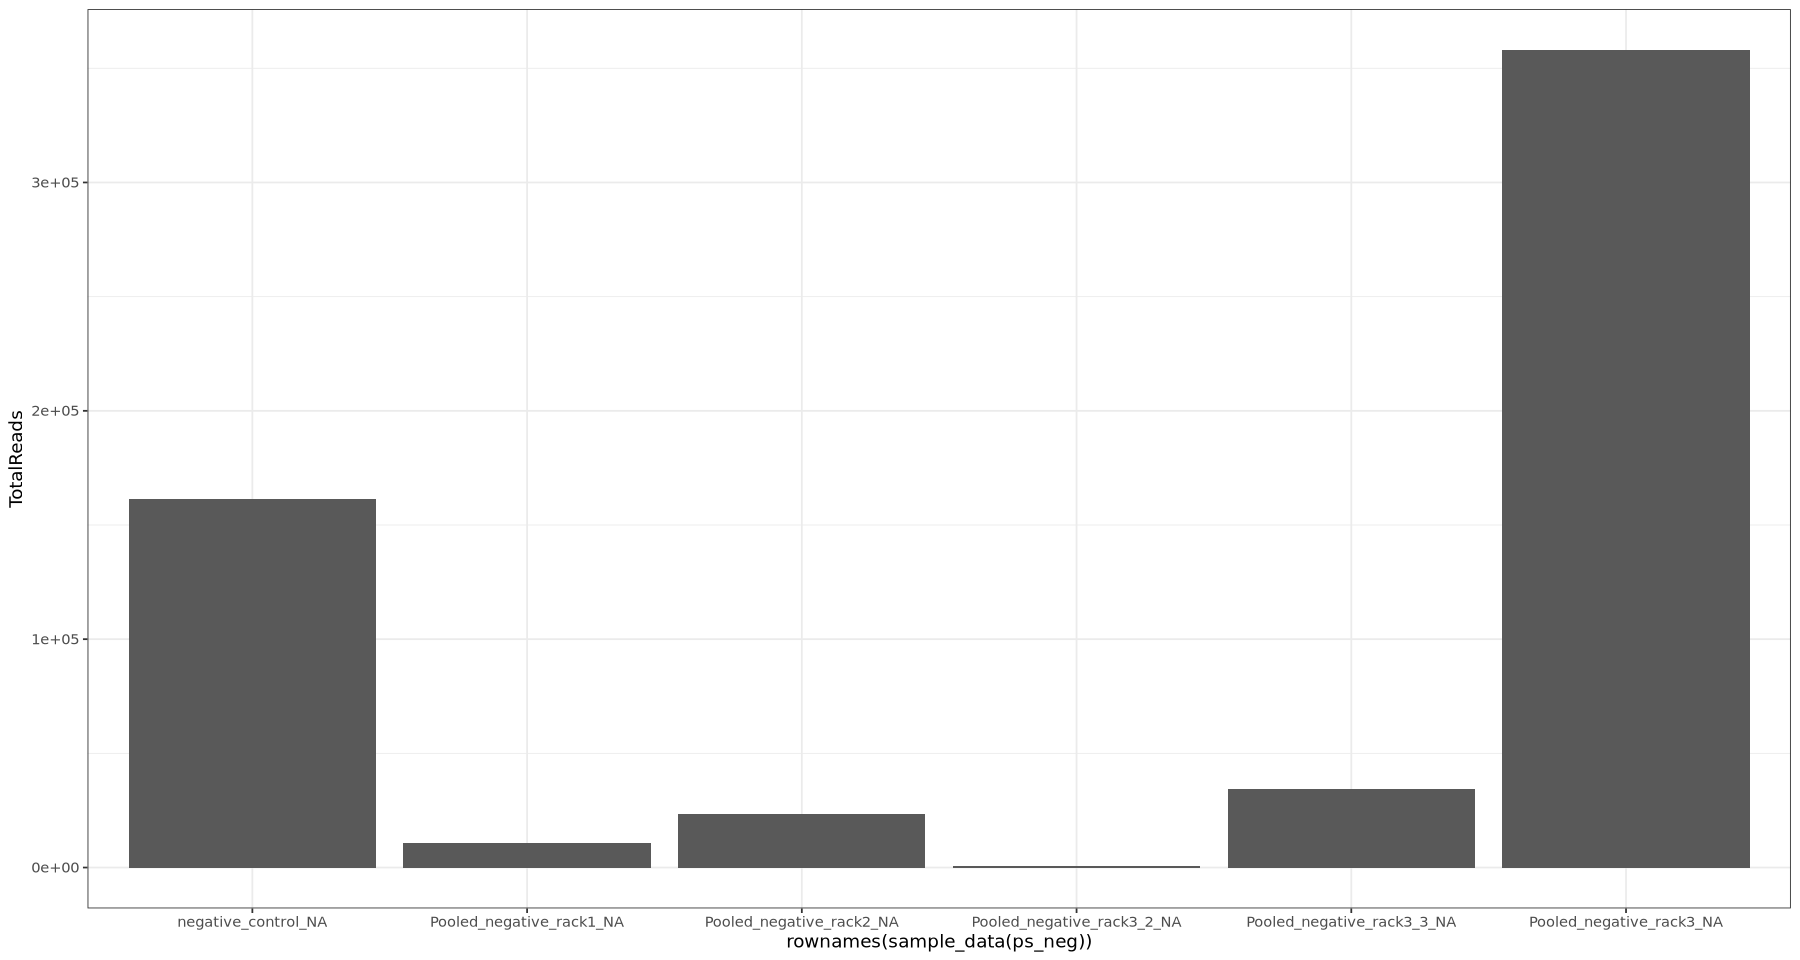

In [14]:
# Check read counts of negatives
readcount_neg <- data.table(as(sample_data(ps_neg), "data.frame"),
                 TotalReads = sample_sums(ps_neg), 
                 keep.rownames = TRUE)
ggplot(readcount_neg, aes(x = rownames(sample_data(ps_neg)), y = TotalReads)) + 
    geom_col() + 
    theme_bw()

Pooled negative rack 3.1 has the most reads out of all samples (~350k) 

In [4]:
# PCoA ordination of negative controls
neg.ord <- ordinate(ps_neg, "PCoA", "bray")

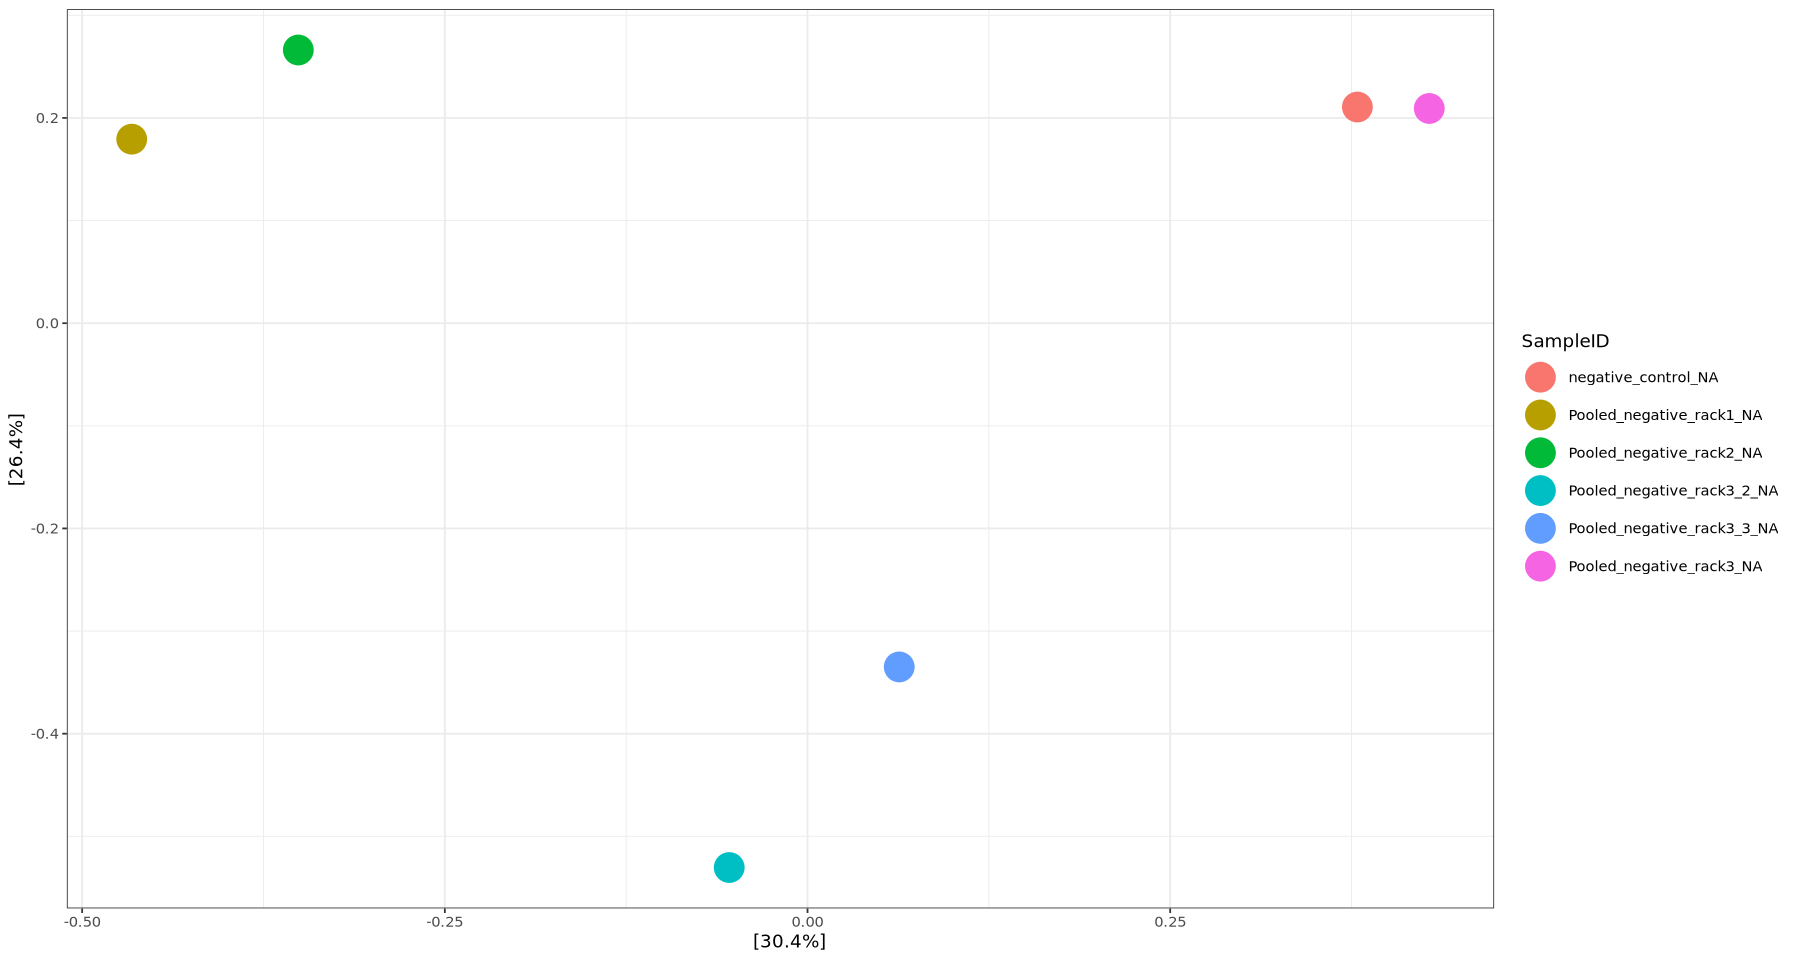

In [8]:
# Plot PCoA but convert row names to column first
sample_data(ps_neg)$SampleID <- rownames(sample_data(ps_neg))
plot_ordination(ps_neg, neg.ord, color = "SampleID") +
    geom_point(size=8) +
    theme_bw()

- Sample negative control + pooled negative control 3.1 () cluster - this kinda makes sense, but curious about the overlap with other samples
- Pooled negative control 1 + 2 cluster - number of reads > 10,000 for each negative control  
- Pooled negative control 3.2 + 3.3 cluster - only 3.2 has < 10,000 reads

These clusters are likely biased due to sampling depth though (NMDS below shows same pattern)

Square root transformation


Warning message in decostand(x, "max", 2, na.rm = na.rm):
“result contains NaN, perhaps due to impossible mathematical
                 operation
”
Warning message in decostand(x, "total", 1, na.rm = na.rm):
“result contains NaN, perhaps due to impossible mathematical
                 operation
”


Wisconsin double standardization
Run 0 stress 0 
Run 1 stress 9.496186e-05 
... Procrustes: rmse 0.261055  max resid 0.409147 
Run 2 stress 5.548064e-05 
... Procrustes: rmse 0.02378133  max resid 0.03910453 
Run 3 stress 8.152164e-05 
... Procrustes: rmse 0.2444693  max resid 0.4725484 
Run 4 stress 0 
... Procrustes: rmse 0.09338188  max resid 0.1422047 
Run 5 stress 9.878714e-05 
... Procrustes: rmse 0.2428732  max resid 0.3754024 
Run 6 stress 0.2181459 
Run 7 stress 0.2673 
Run 8 stress 0.0004388451 
... Procrustes: rmse 0.1682604  max resid 0.2159178 
Run 9 stress 0.0001009466 
... Procrustes: rmse 0.08375153  max resid 0.1078631 
Run 10 stress 9.680745e-05 
... Procrustes: rmse 0.2496194  max resid 0.3625296 
Run 11 stress 0.2673072 
Run 12 stress 9.33895e-05 
... Procrustes: rmse 0.2348845  max resid 0.3321275 
Run 13 stress 0.2181459 
Run 14 stress 8.768014e-05 
... Procrustes: rmse 0.1893964  max resid 0.3294547 
Run 15 stress 9.006867e-05 
... Procrustes: rmse 0.2167952  max

Warning message in metaMDS(veganifyOTU(physeq), distance, ...):
“stress is (nearly) zero: you may have insufficient data”
Warning message in postMDS(out$points, dis, plot = max(0, plot - 1), ...):
“skipping half-change scaling: too few points below threshold”
Warning message in metaMDS(veganifyOTU(physeq), distance, ...):
“WA scores were not calculated due to missing values”


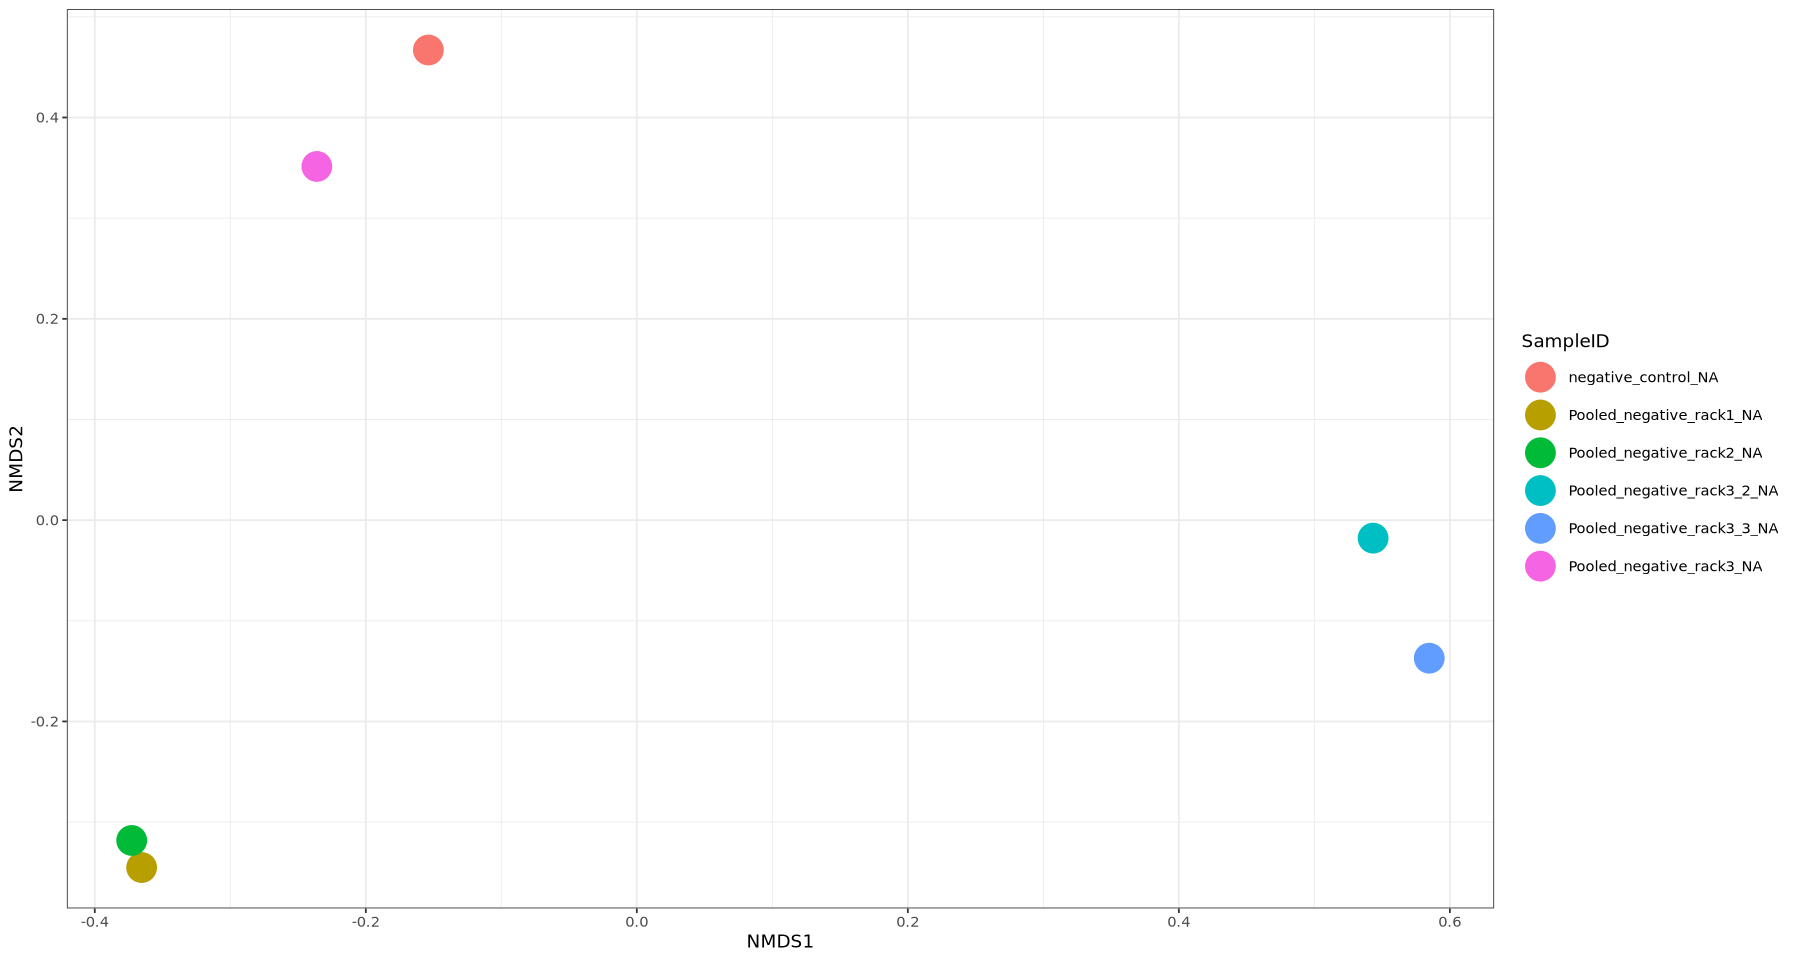

In [21]:
# NMDS ordination and plot
neg.ord.nmds <- ordinate(ps_neg, "NMDS", "bray")
plot_ordination(ps_neg, neg.ord.nmds, color = "SampleID") +
    geom_point(size=8) +
    theme_bw()

#### PCoA all samples

In [9]:
# Add label to negative controls in the tissue column of the sample_data df
sample_data(ps)$Tissue[grepl("negative", sample_names(ps))] <- "Negative_control"

In [10]:
# PCoA ordination of all samples
all.ord <- ordinate(ps, "PCoA", "bray")

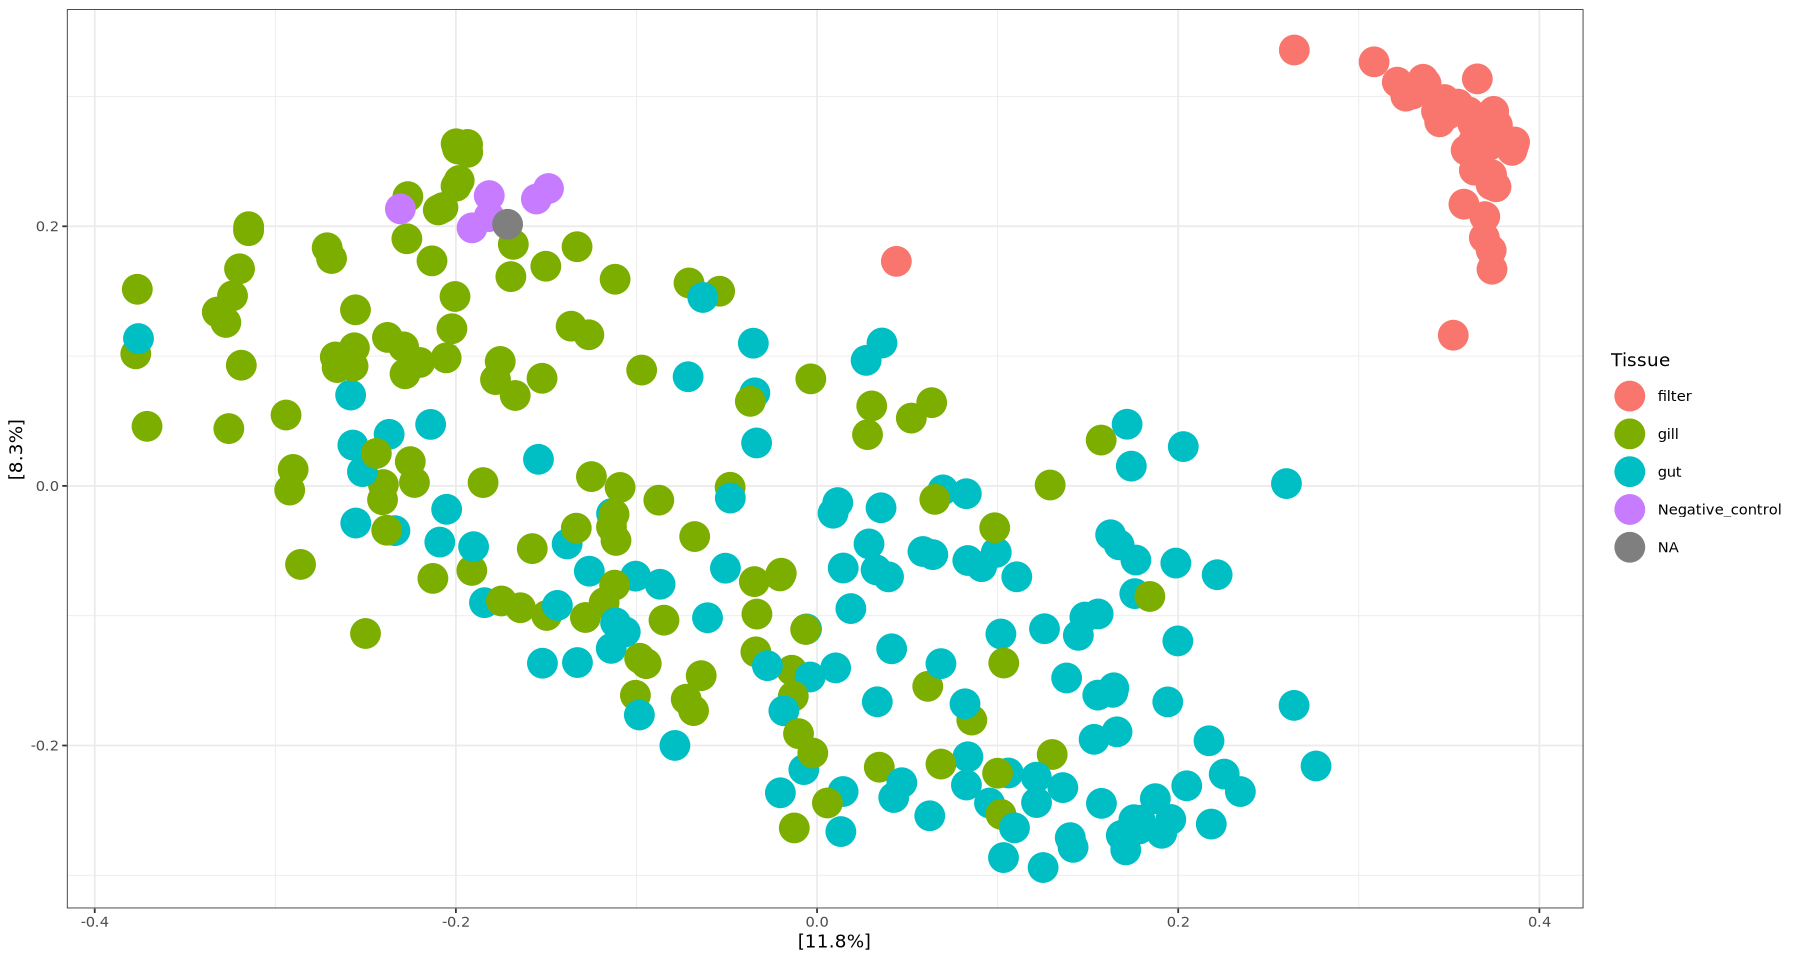

In [11]:
# Plot PCoA of all samples
plot_ordination(ps, all.ord, color = "Tissue") +
    geom_point(size=8) +
    theme_bw()

- Filter separates very neatly from the tissue samples
- Gill and gut have a large overlap but some distinction along the x-axis component
- Negative controls cluster but within the gill tissue...
  
*Note: the NA is the positive control*

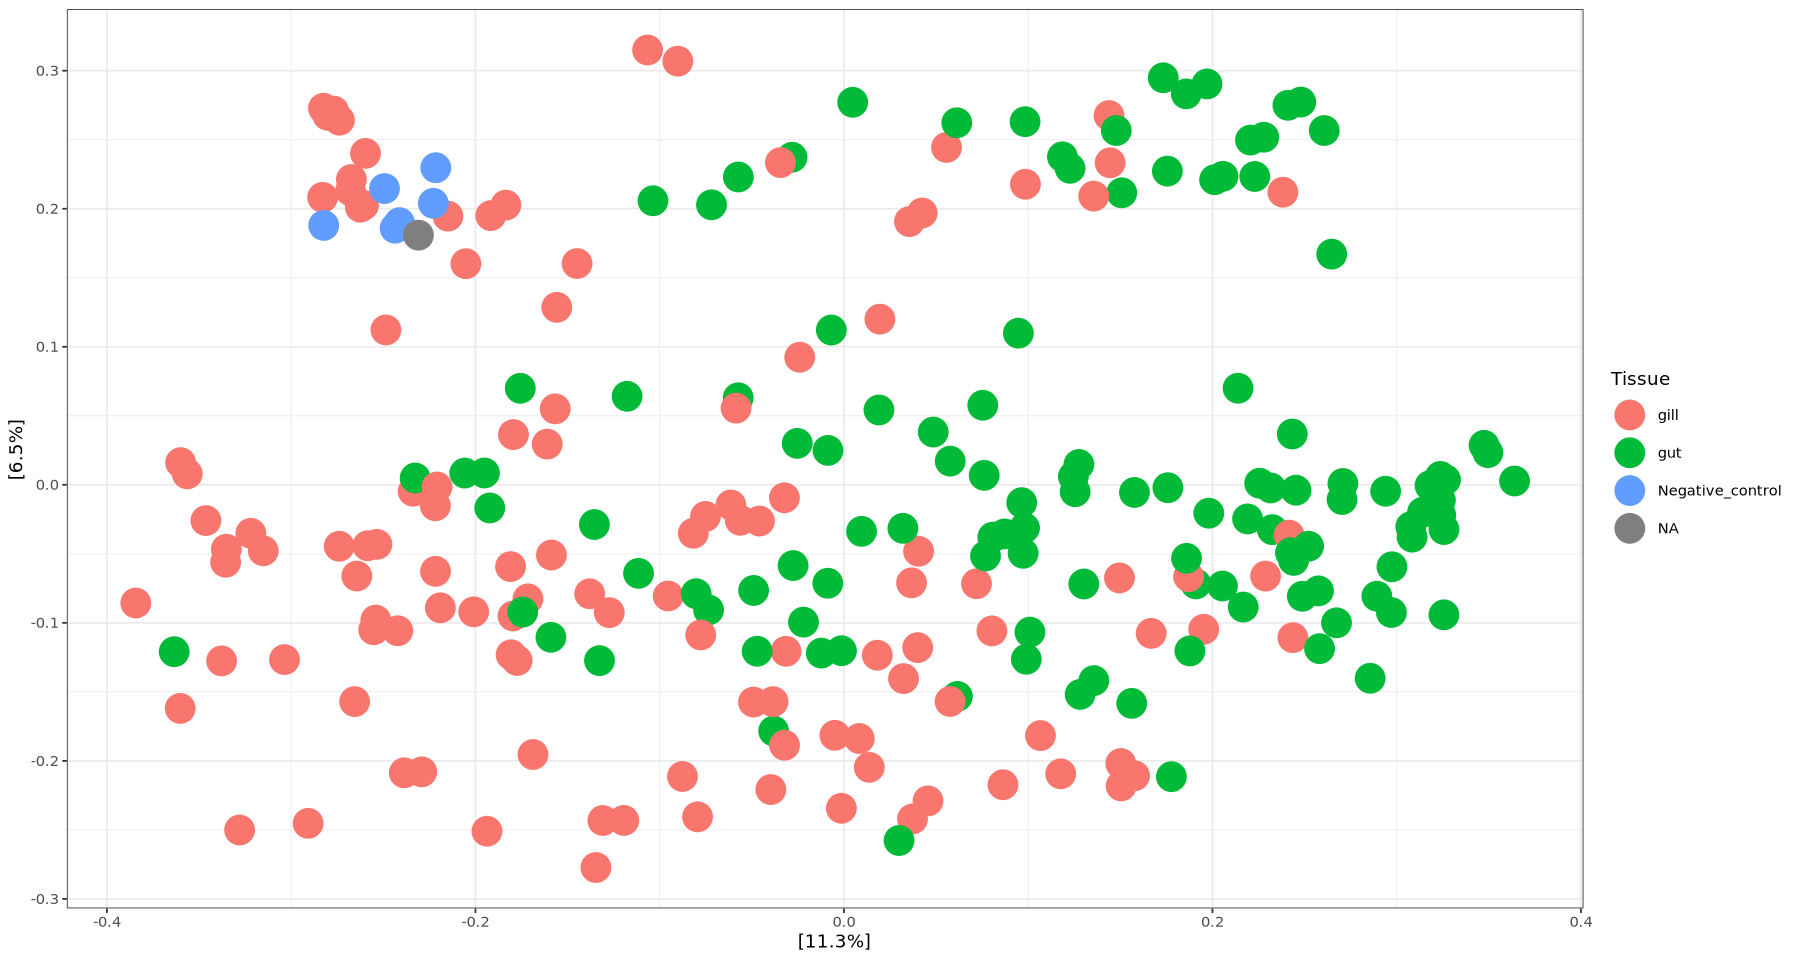

In [12]:
# Remove filter samples from PCoA and plot
ps_tissue <- subset_samples(ps, is.na(Tissue) | Tissue != "filter")
tissue.ord <- ordinate(ps_tissue, "PCoA", "bray")
plot_ordination(ps_tissue, tissue.ord, color = "Tissue") +
    geom_point(size=8) +
    theme_bw()

- Curious if the date of indexing can explain why some of those gill samples cluster with the negative controls
- Could also just look at Phase 1 samples to simplify

#### PCoA phase 1 samples

In [16]:
# Label negative controls as phase 1 in the sample_data df
sample_data(ps_tissue)$Phase[grepl("negative", sample_names(ps_tissue))] <- "1"
sample_data(ps_tissue)$Phase[grepl("Positive", sample_names(ps_tissue))] <- "1"
sample_data(ps_tissue)$Tissue[grepl("Positive", sample_names(ps_tissue))] <- "Positive_control"

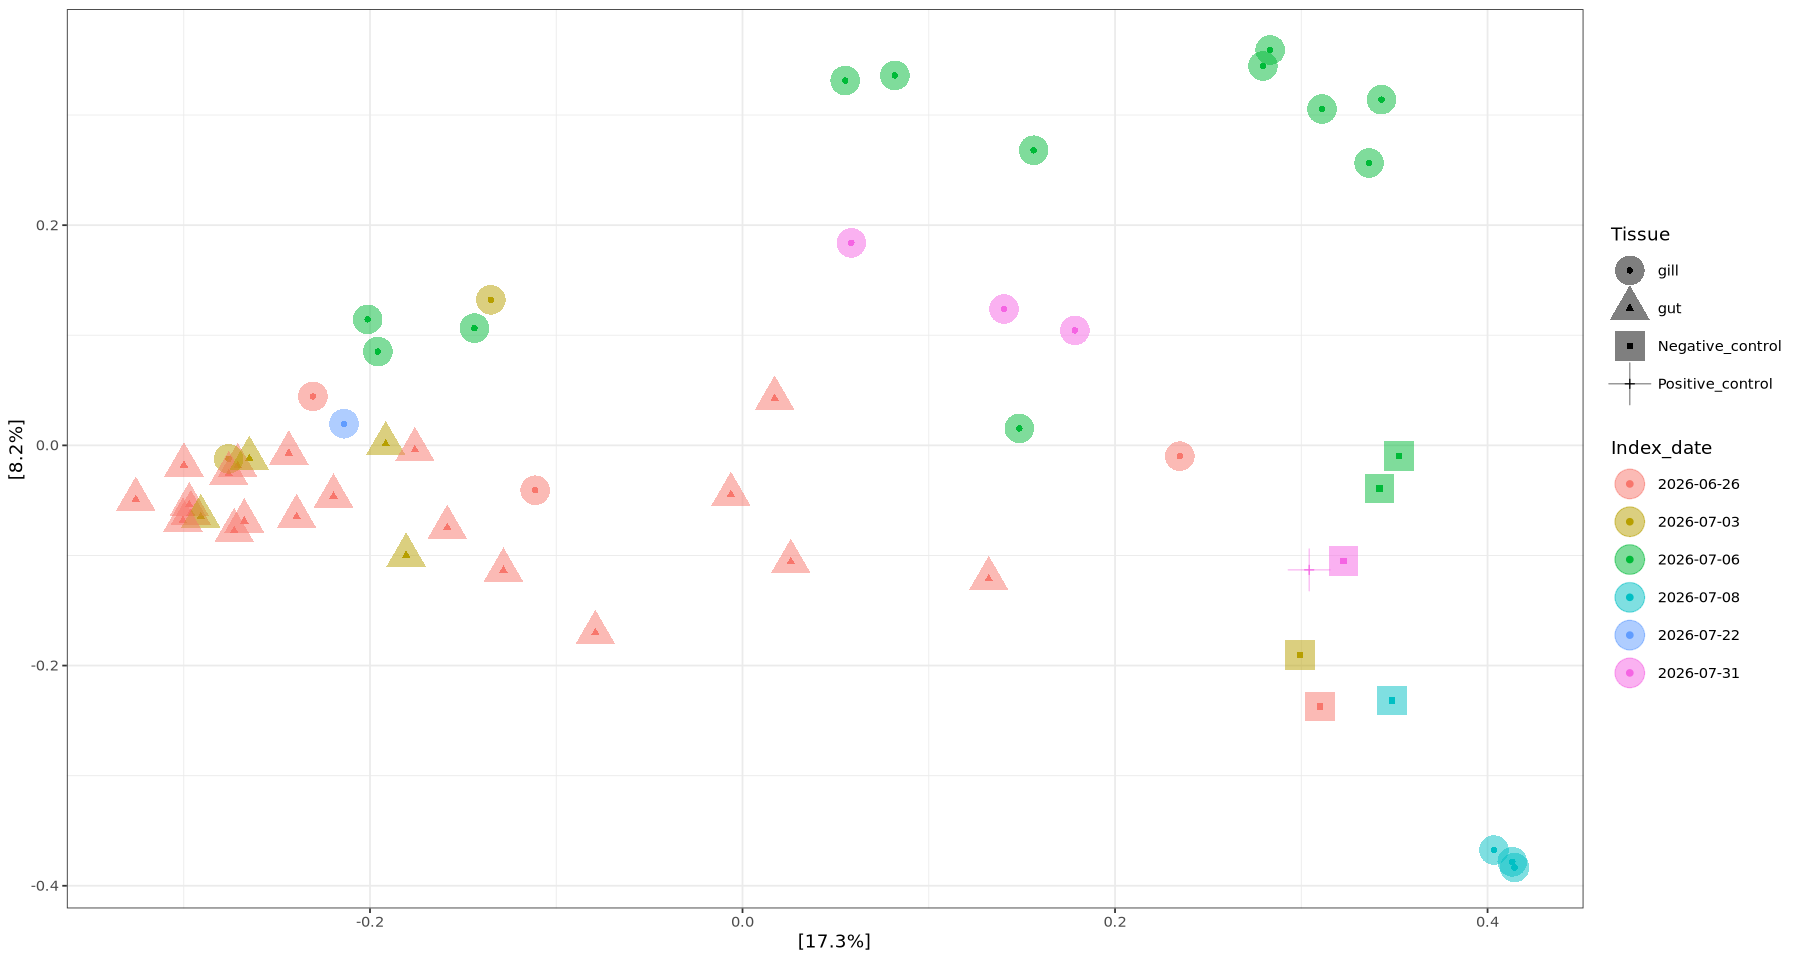

In [17]:
# Subset and oordinate Phase 1 samples 
ps_p1 <- subset_samples(ps_tissue, Phase == 1)
p1.ord <- ordinate(ps_p1, "PCoA", "bray")
plot_ordination(ps_p1, p1.ord, color = "Index_date", shape = "Tissue") +
    geom_point(size=8, alpha=0.5) +
    theme_bw()

Looking at just phase 1 samples, the negative controls and positive control seem to cluster more closely than with the gill tissue, except for those samples indexed on July 8th

In [25]:
# Investigate samples indexed on July 8th
subset_samples(sample_data(ps_tissue), Index_date == "2026-07-08")

,Year,Combined_treat,Phase_1_treat,Phase_1_rep,Phase_2_treat,Phase_2_rep,Tag,Phase,Tissue,Concentration,⋯,Pooled_notes,Index_primers,Index_date,Index_volume,Clean_date,Clean_date_2,Gel_extraction,Final_concentration,X25ng,Notes
,<chr>,<chr>,<chr>,<int>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,⋯,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
2024_Both01_Null_O03_gill,2024,BNA,Both,1,NA,NA,O03,1,gill,0.980,⋯,,BFi-13,2026-07-08,3,7/10/26,,7/22/26,4.98,5.02,
2024_Both04_Null_O32_gill,2024,BNA,Both,4,NA,NA,O32,1,gill,0.972,⋯,faint,BFi-13,2026-07-08,3,7/10/26,,7/22/26,3.30,7.58,
2024_Both05_Both06_O69_gill,2024,BB,Both,5,Both,6,O69,2,gill,24.800,⋯,,BFi-13,2026-07-08,2,7/10/26,,7/22/26,5.94,4.21,
2024_Cont03_Null_W21_gill,2024,CNA,Cont,3,NA,NA,W21,1,gill,6.000,⋯,,BFi-13,2026-07-08,2,7/10/26,,7/22/26,5.42,4.61,
2024_Cont04_Cont06_W67_gill,2024,CC,Cont,4,Cont,6,W67,2,gill,32.500,⋯,,BFi-13,2026-07-08,2,7/10/26,,7/22/26,4.28,5.84,
2024_Warm01_Hyp05_G49_gill,2024,WH,Warm,1,Hyp,5,G49,2,gill,4.160,⋯,,BFi-13,2026-07-08,3,7/10/26,,7/22/26,3.50,7.14,
Pooled_negative_rack3_2_NA,Pooled,NA,NA,NA,rack,3,2,2,Negative_control,NA,⋯,,BFi-13,2026-07-08,1,7/10/26,NA,NA,2.20,3.00,Rack 3 negative


In [ ]:
# Save phase 1 phyloseq object
saveRDS(ps_p1, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps_p1.rds")

Weird, these are all of the samples that have < 10,000 reads - I wonder if something went wrong with the indexing, but I used the same primers during other indexing runs (i.e. July 6th) just different i5 + i7 combinations

#### PCoA phase 2 samples

In [22]:
# Label negative controls as phase 2 in the sample_data df
sample_data(ps_tissue)$Phase[grepl("negative", sample_names(ps_tissue))] <- "2"
sample_data(ps_tissue)$Phase[grepl("Positive", sample_names(ps_tissue))] <- "2"
sample_data(ps_tissue)$Tissue[grepl("Positive", sample_names(ps_tissue))] <- "Positive_control"

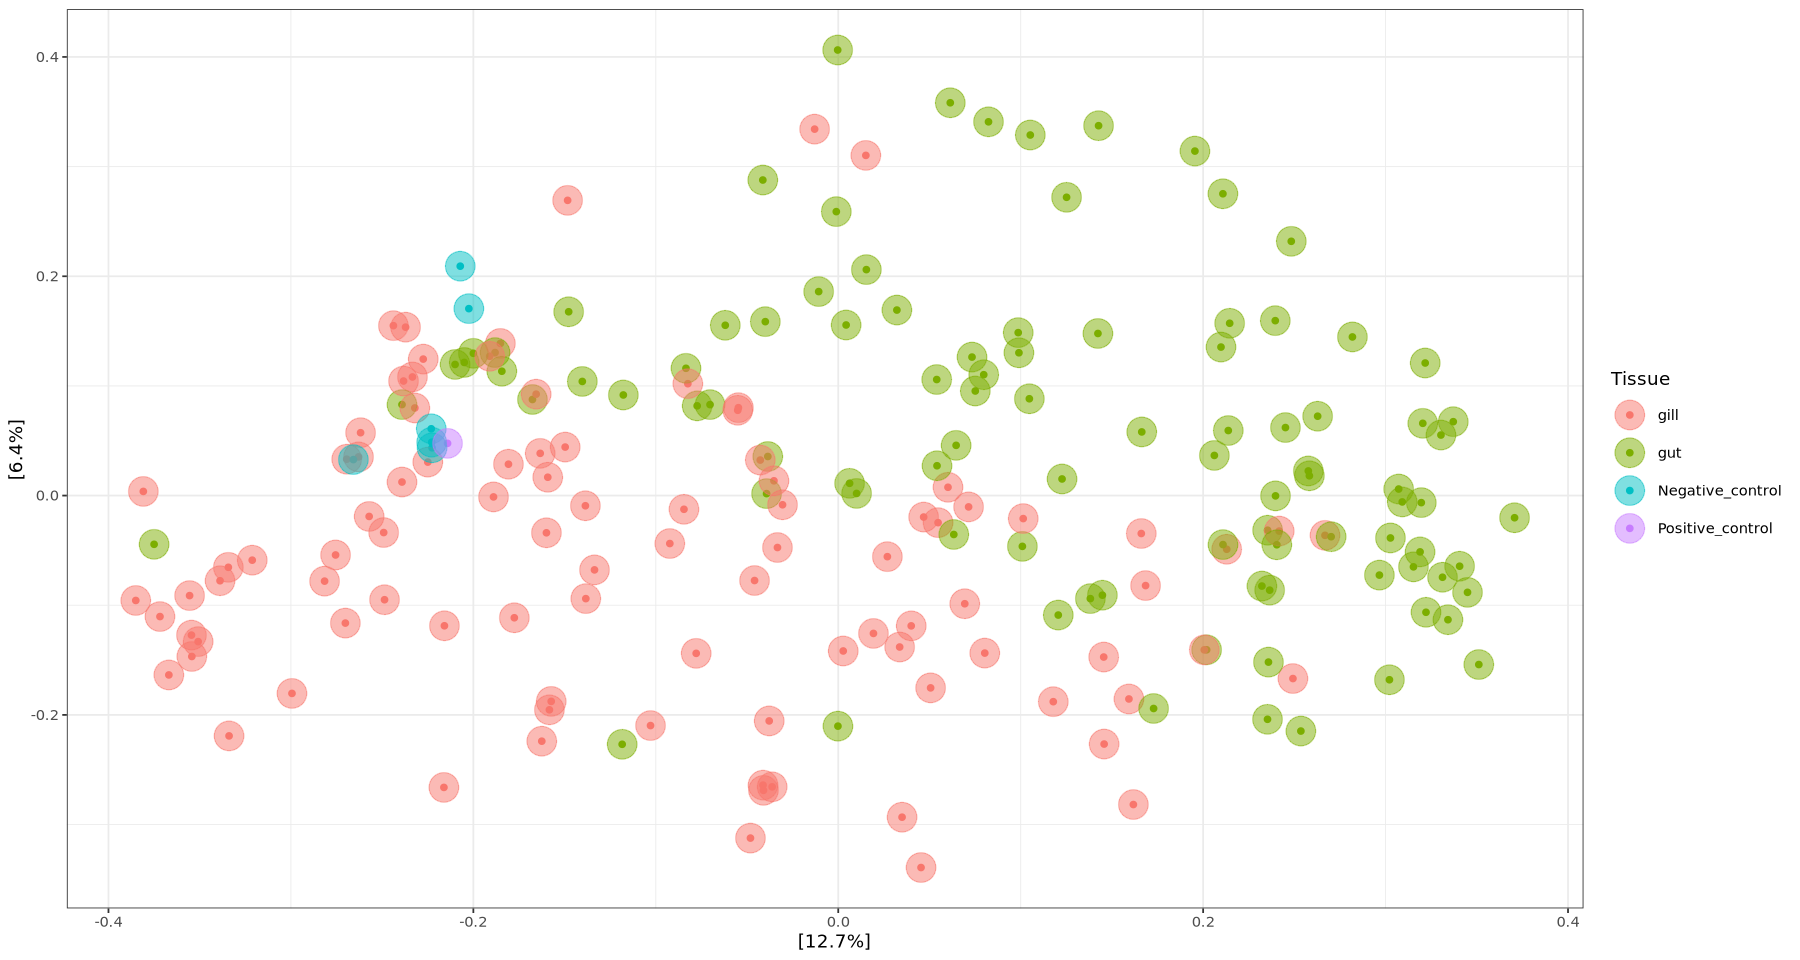

In [27]:
# Subset and oordinate Phase 1 samples 
ps_p2 <- subset_samples(ps_tissue, Phase == 2)
p2.ord <- ordinate(ps_p2, "PCoA", "bray")
plot_ordination(ps_p2, p2.ord, color = "Tissue") +
    geom_point(size=8, alpha=0.5) +
    theme_bw()

In [28]:
# Save phase 2 phyloseq object
saveRDS(ps_p2, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps_p2.rds")

#### Index dates

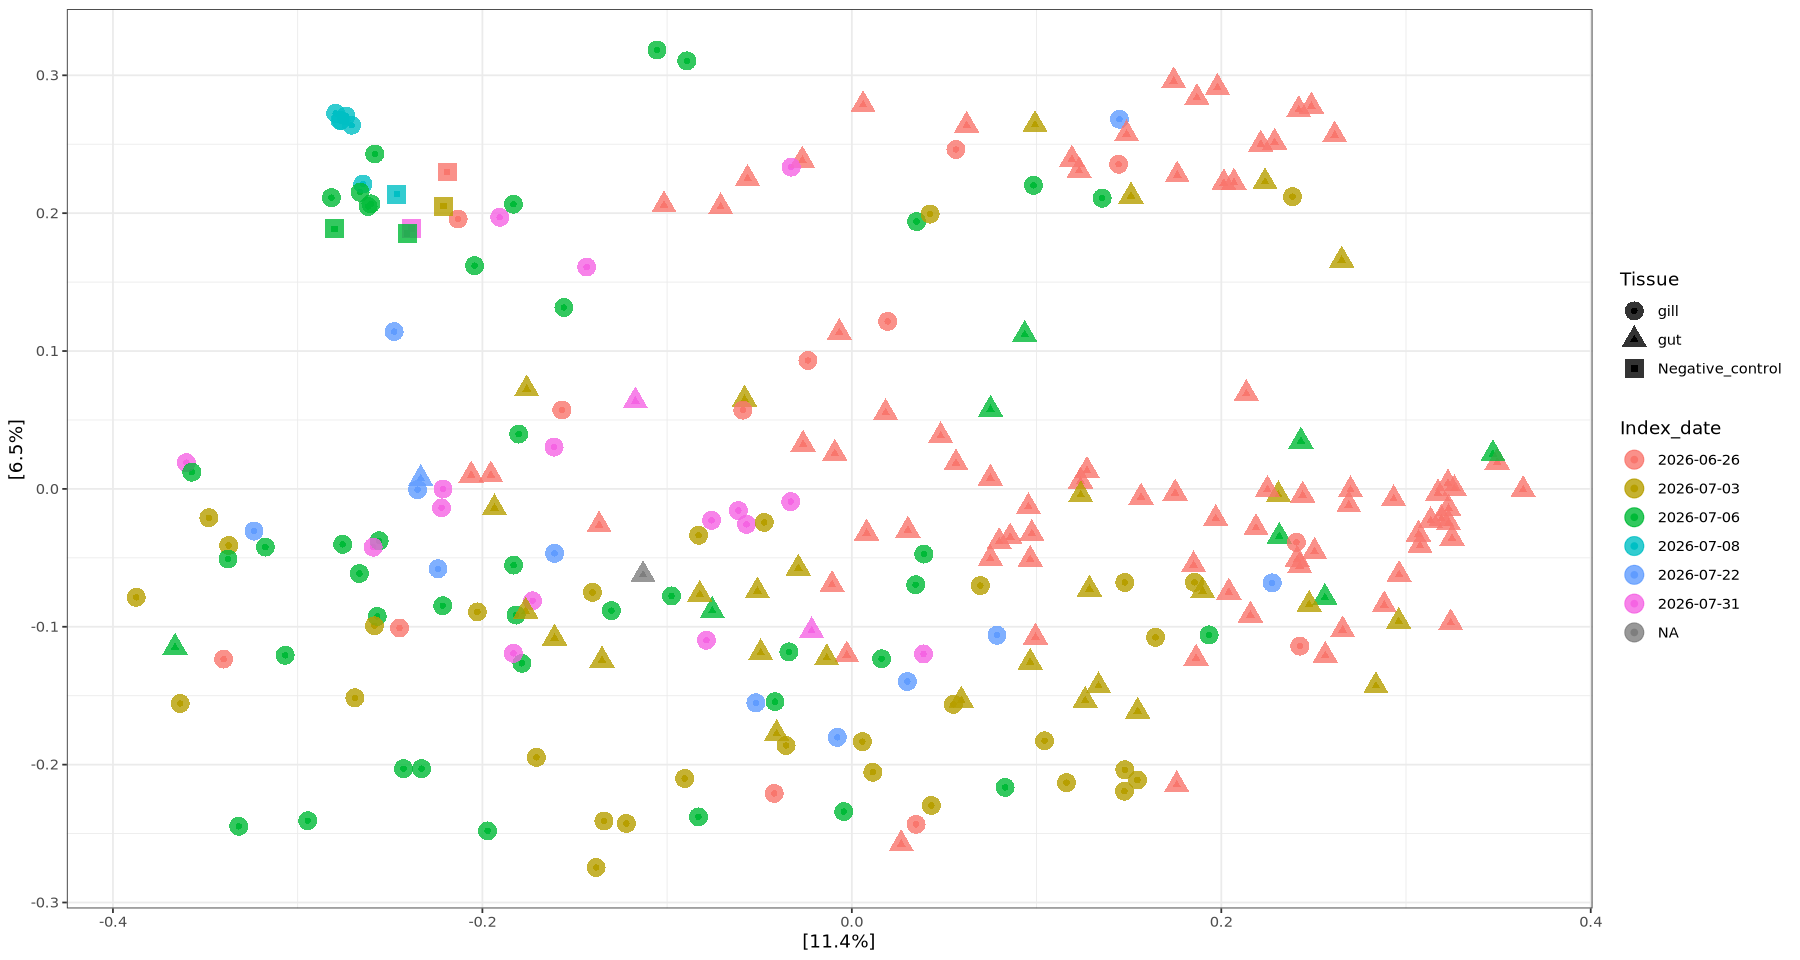

In [28]:
plot_ordination(ps_tissue, tissue.ord, color = "Index_date", shape = "Tissue") +
    geom_point(size=5, alpha=0.8) +
    theme_bw()

- Interesting only ~5 samples were indexed on July 8th and that they cluster with the pooled negative (3.2)
- Only a small proportion of samples indexed on July 6th cluster with the negative sample and pooled negative (3.1) but these are the negatives with lots of reads
    - Wonder if there is a way to try to isolate those samples, or if there is a common feature to them

In [ ]:
# Investigate samples indexed on July 6th
ps_july6 <- subset_samples(ps_tissue, Index_date == "2026-07-06")
july6.ord <- ordinate(ps_july6, "PCoA", "bray")

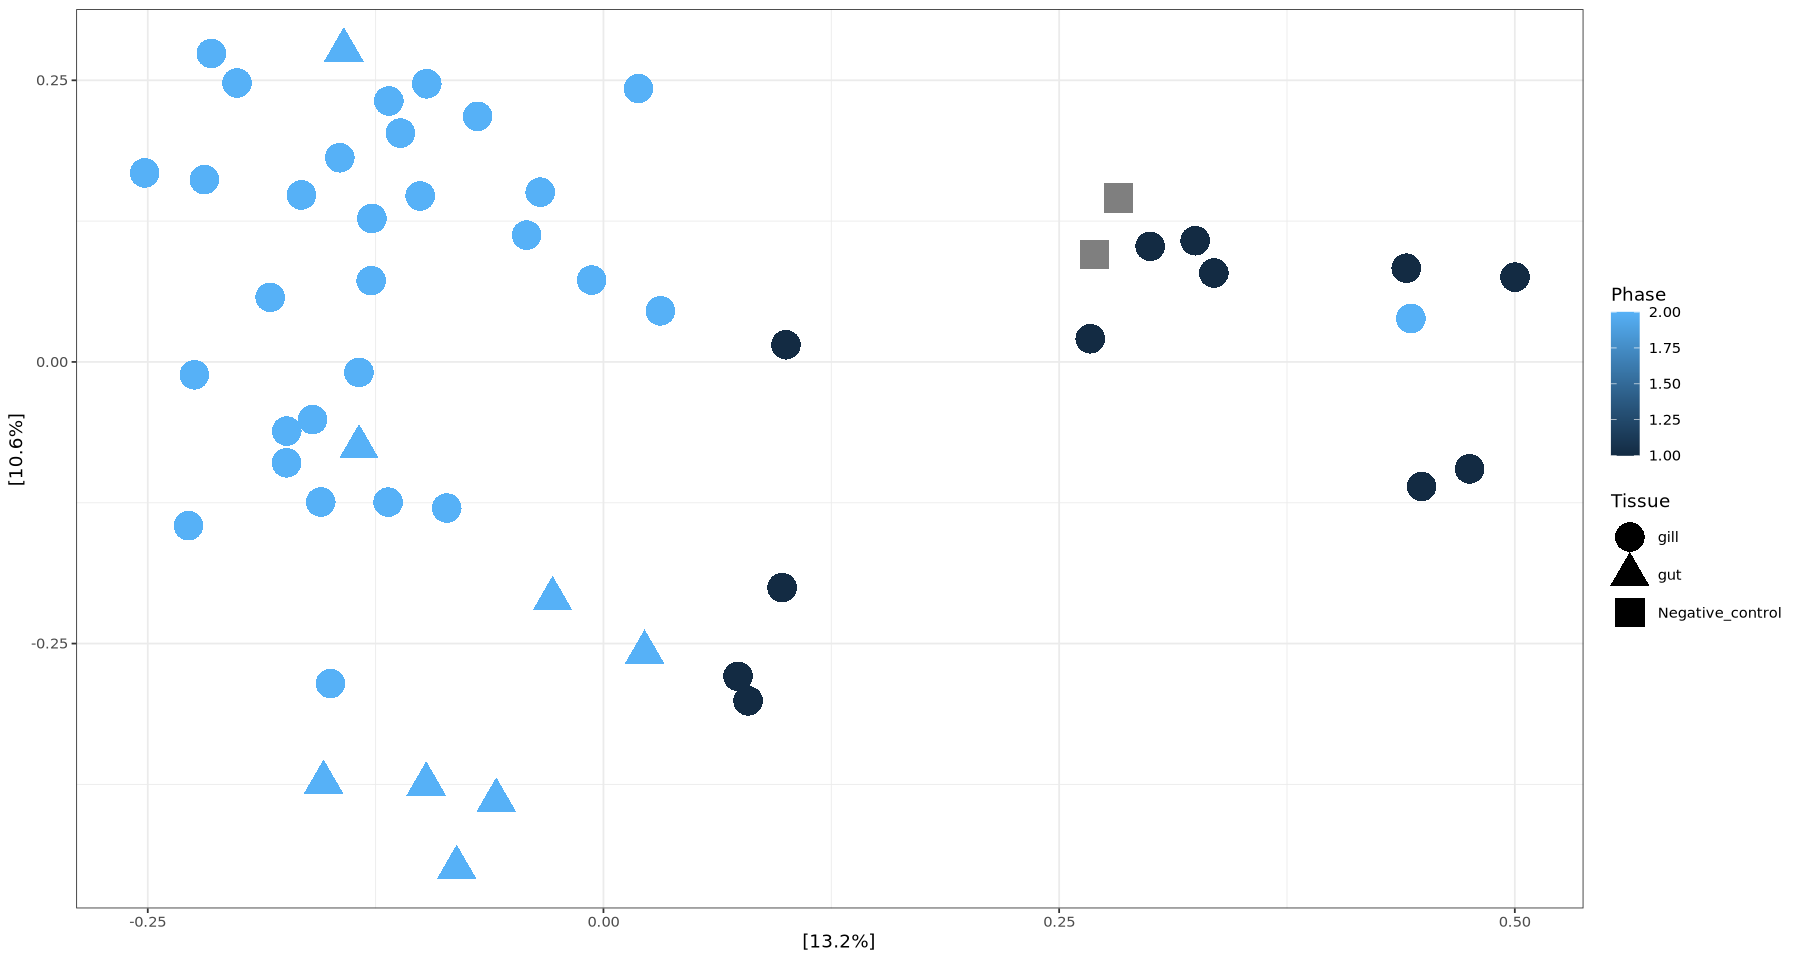

In [68]:
plot_ordination(ps_july6, july6.ord, color = "Phase", shape = "Tissue") +
    geom_point(size=8) +
    theme_bw()

Only pattern relating the four samples that cluster with the negative sample and pooled negative is that they are from phase 1, but this is not exclusive since all phase 1 samples indexed this date don't cluster. Other metadata features I used to check for correlations: 
- Adapters
- Gel extraction
- Date of first PCR
- DNA dilution of first PCR
- Double banded
- Pool date
- Clean date
- Final concentration

Next step is probably to look at the diversity and composition plots of these samples

##### Other PCoAs

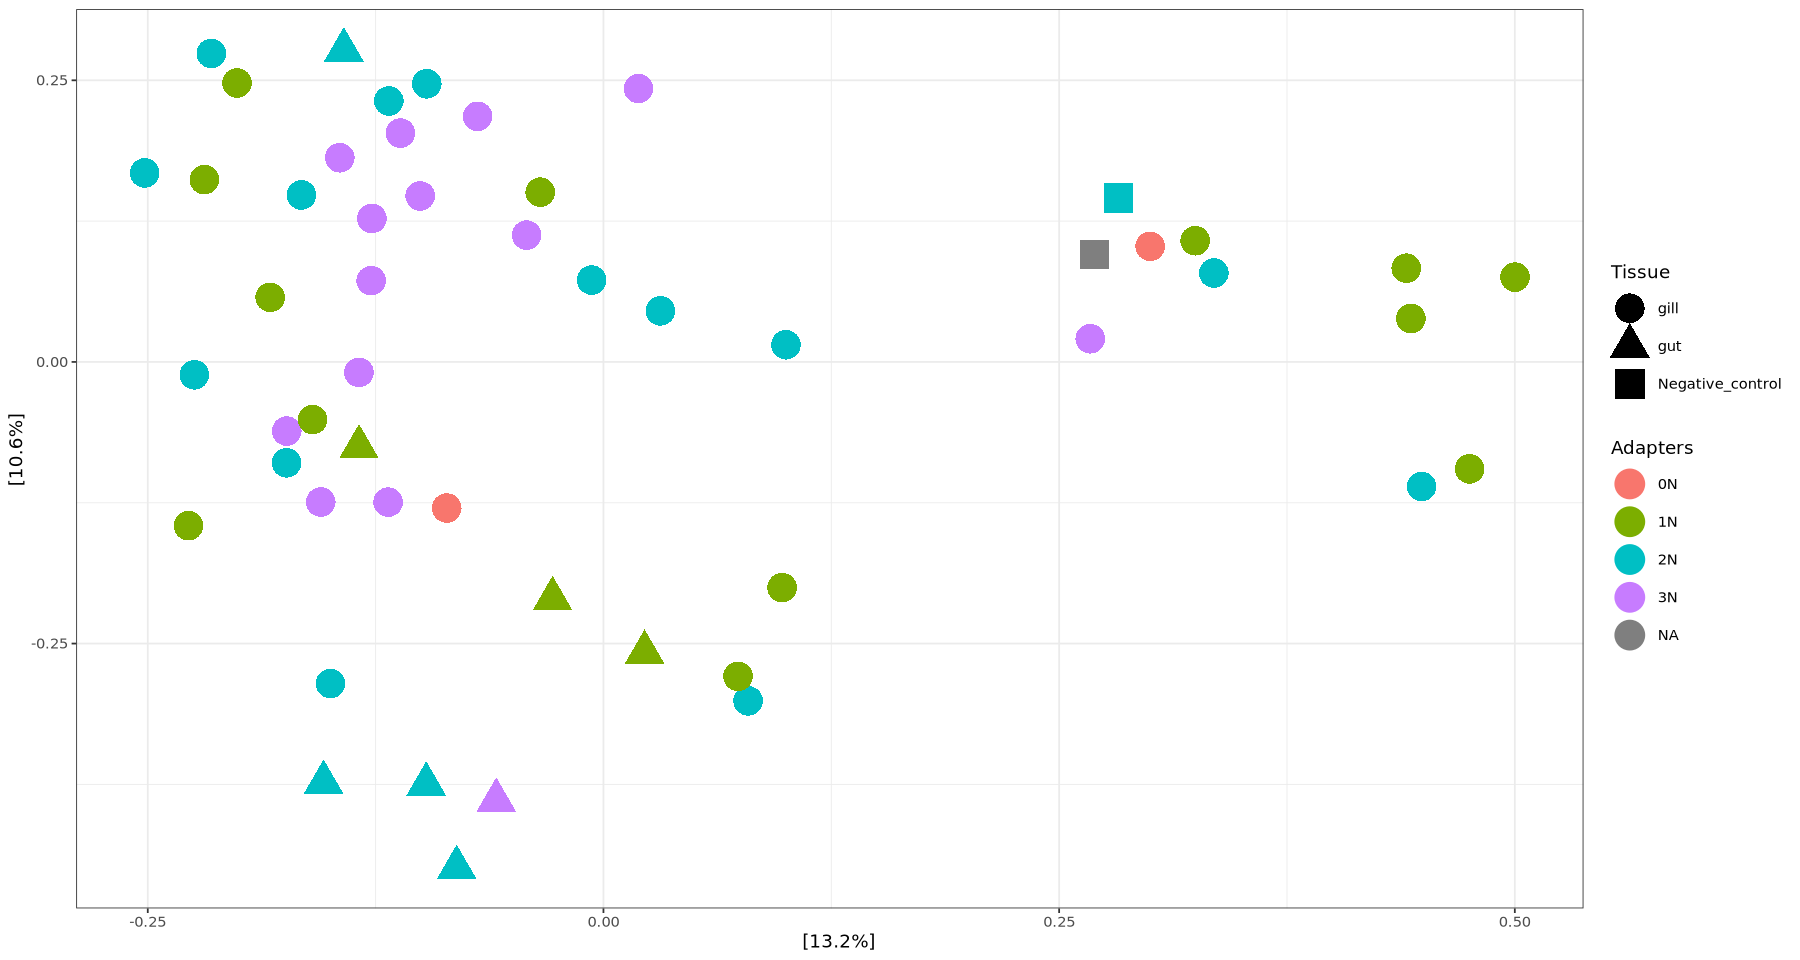

In [49]:
plot_ordination(ps_july6, july6.ord, color = "Adapters", shape = "Tissue") +
    geom_point(size=8) +
    theme_bw()

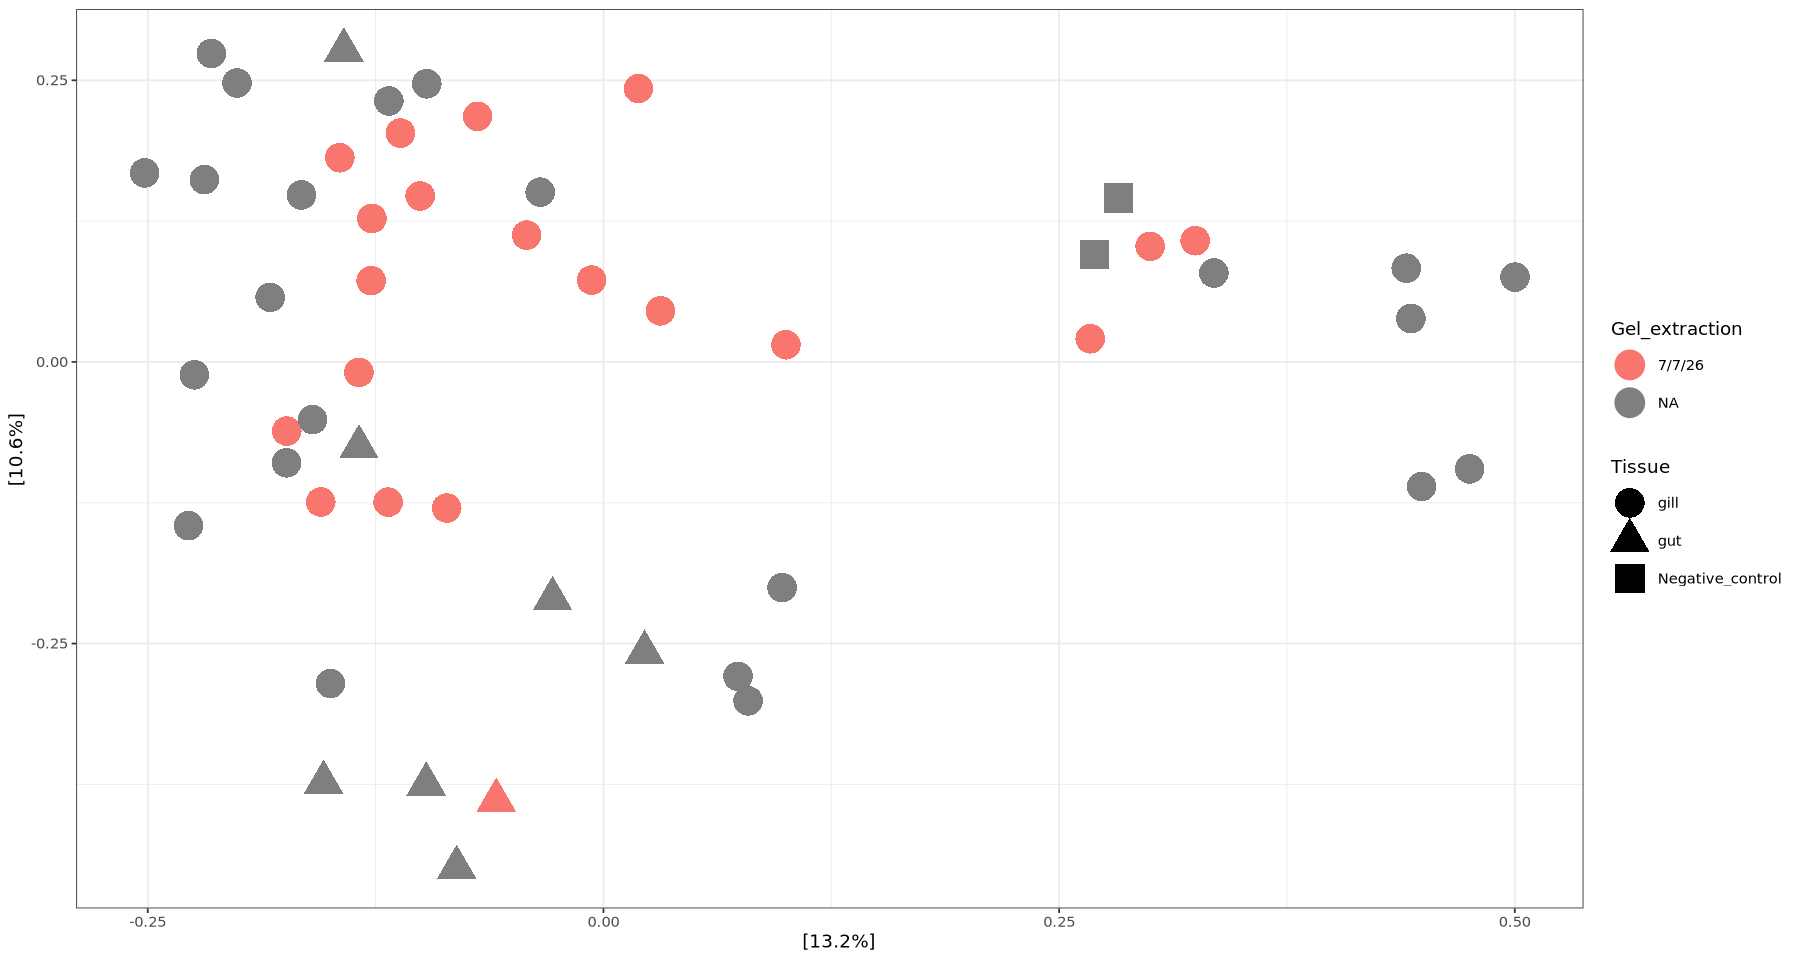

In [50]:
plot_ordination(ps_july6, july6.ord, color = "Gel_extraction", shape = "Tissue") +
    geom_point(size=8) +
    theme_bw()

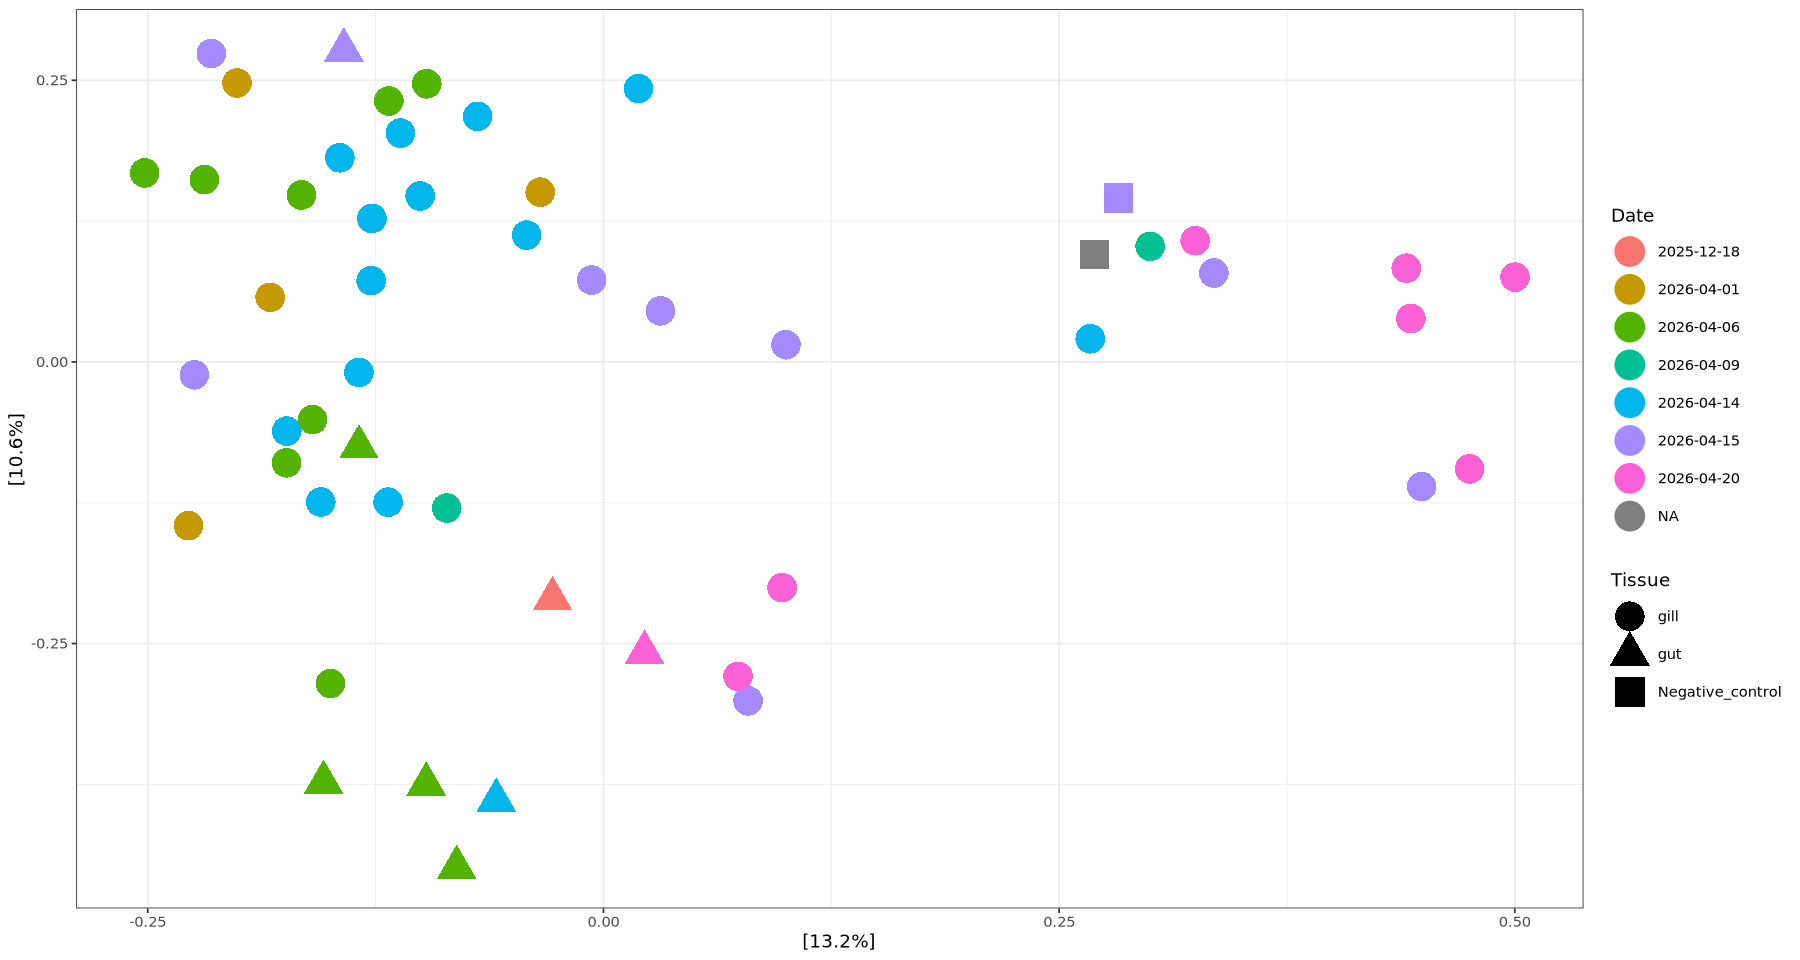

In [52]:
plot_ordination(ps_july6, july6.ord, color = "Date", shape = "Tissue") +
    geom_point(size=8) +
    theme_bw()

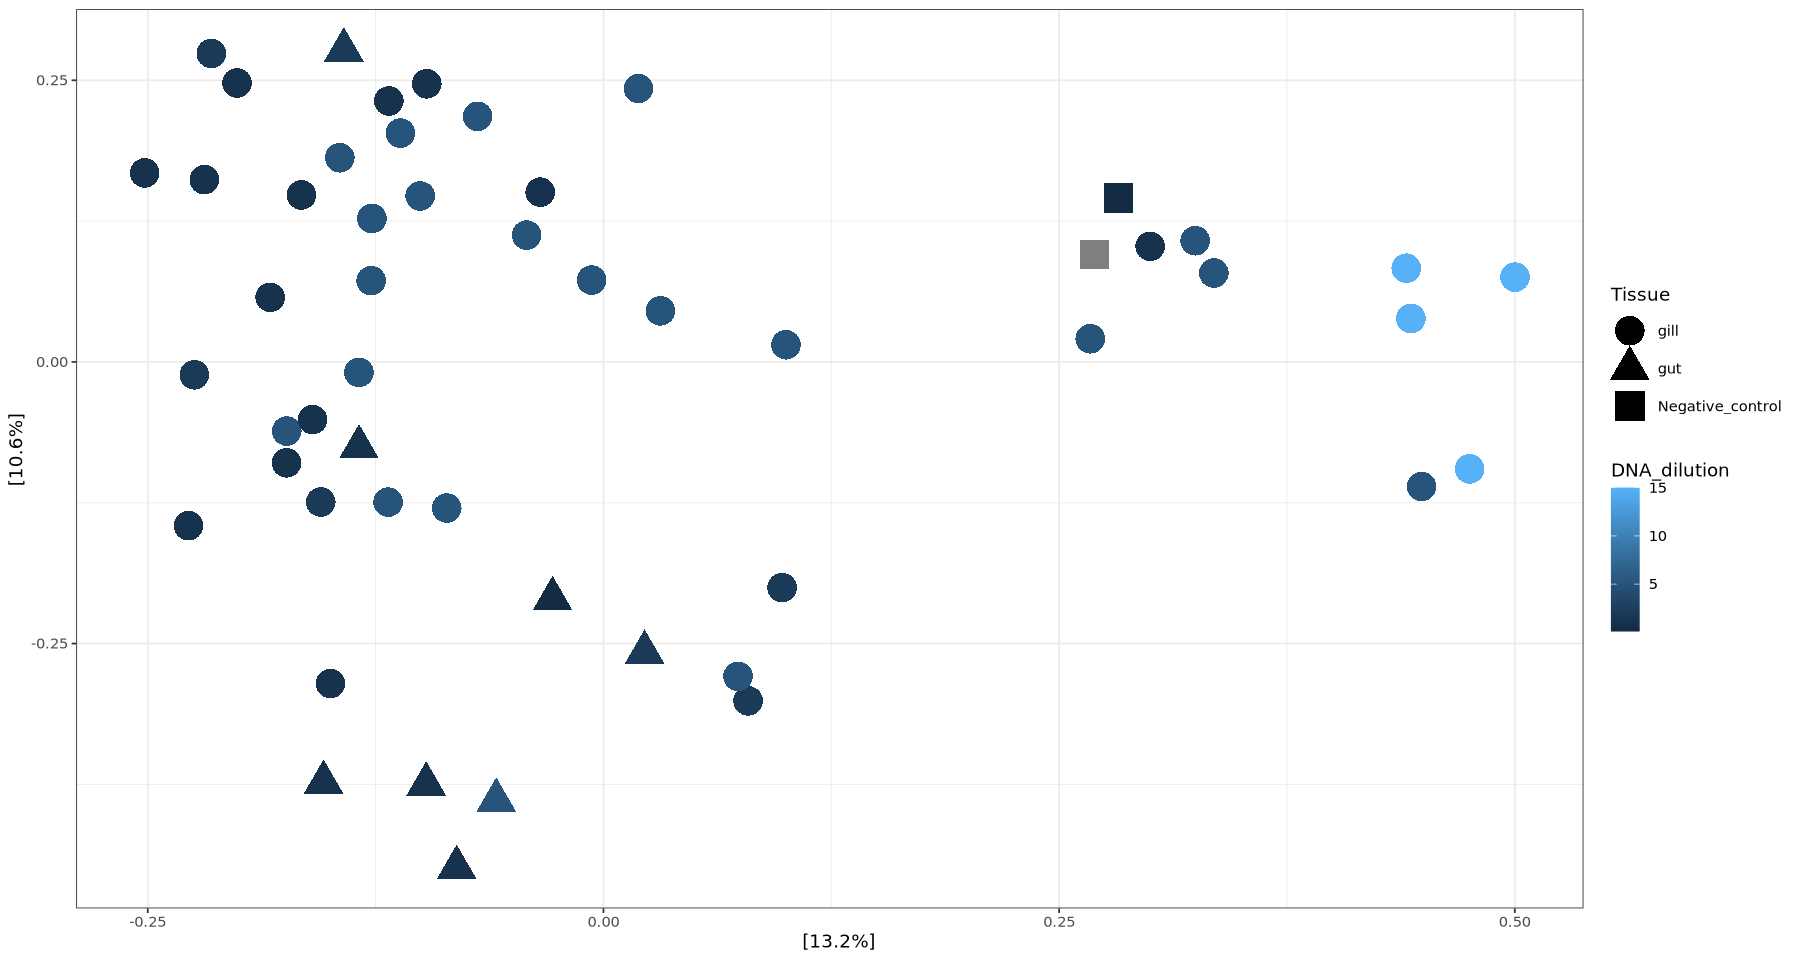

In [51]:
plot_ordination(ps_july6, july6.ord, color = "DNA_dilution", shape = "Tissue") +
    geom_point(size=8) +
    theme_bw()

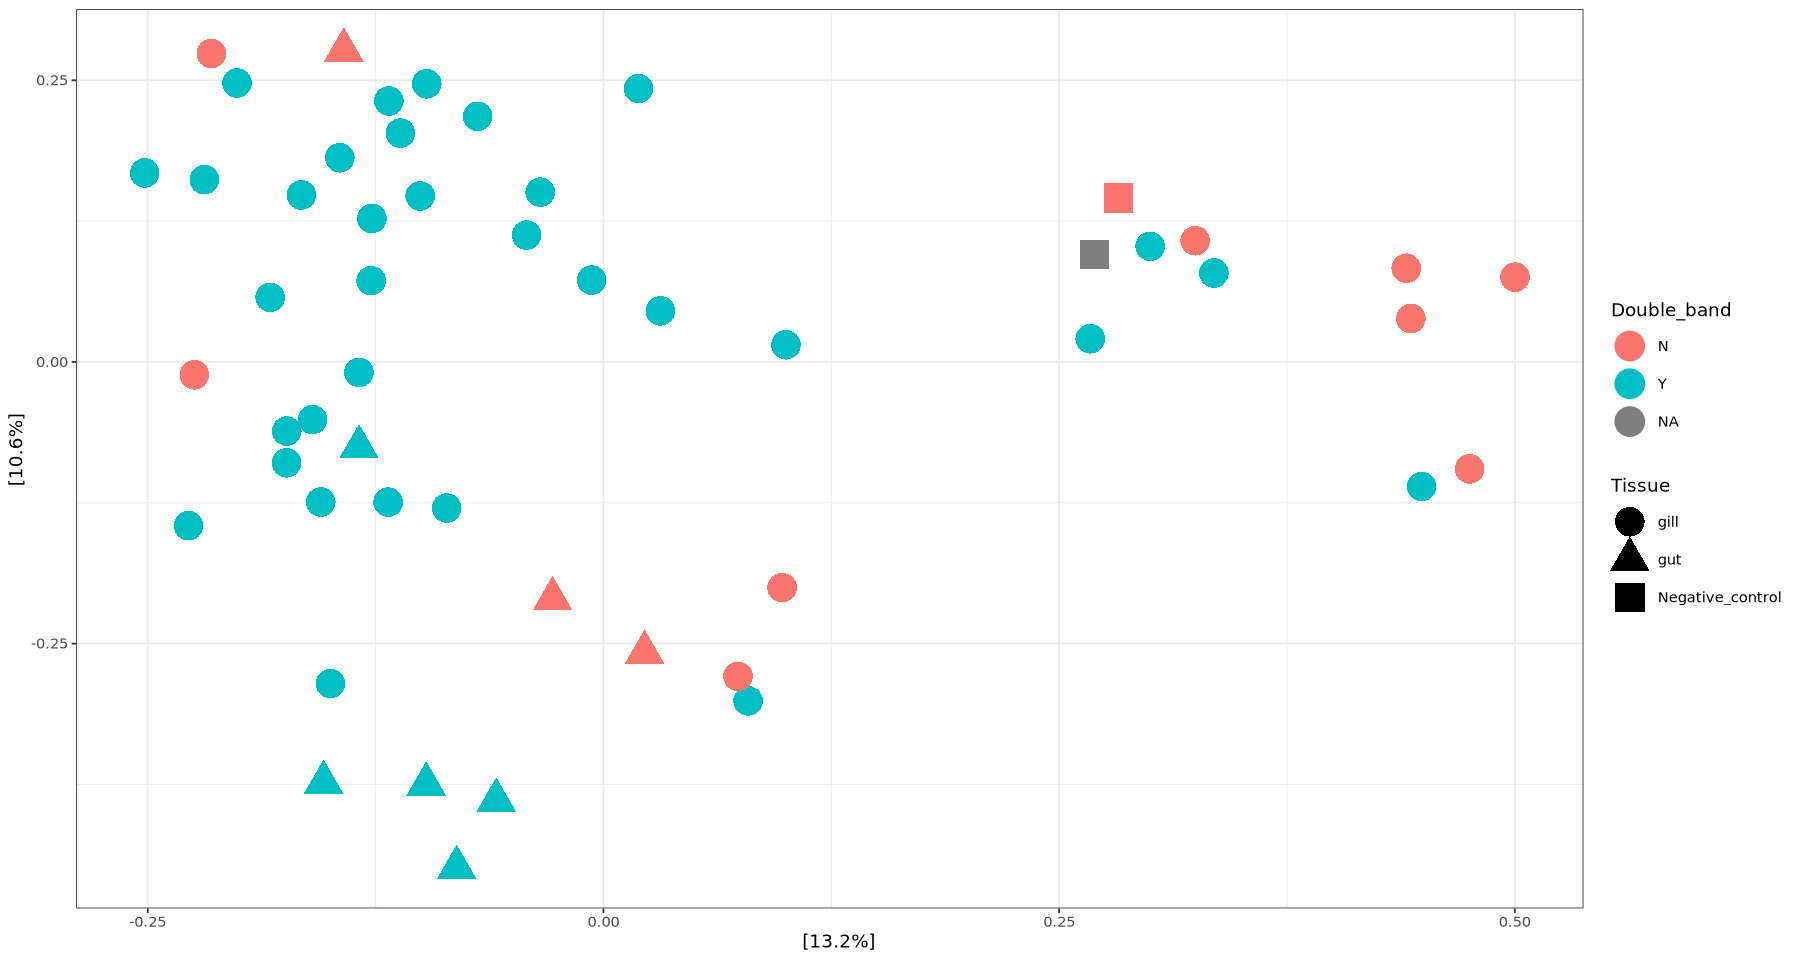

In [53]:
plot_ordination(ps_july6, july6.ord, color = "Double_band", shape = "Tissue") +
    geom_point(size=8) +
    theme_bw()

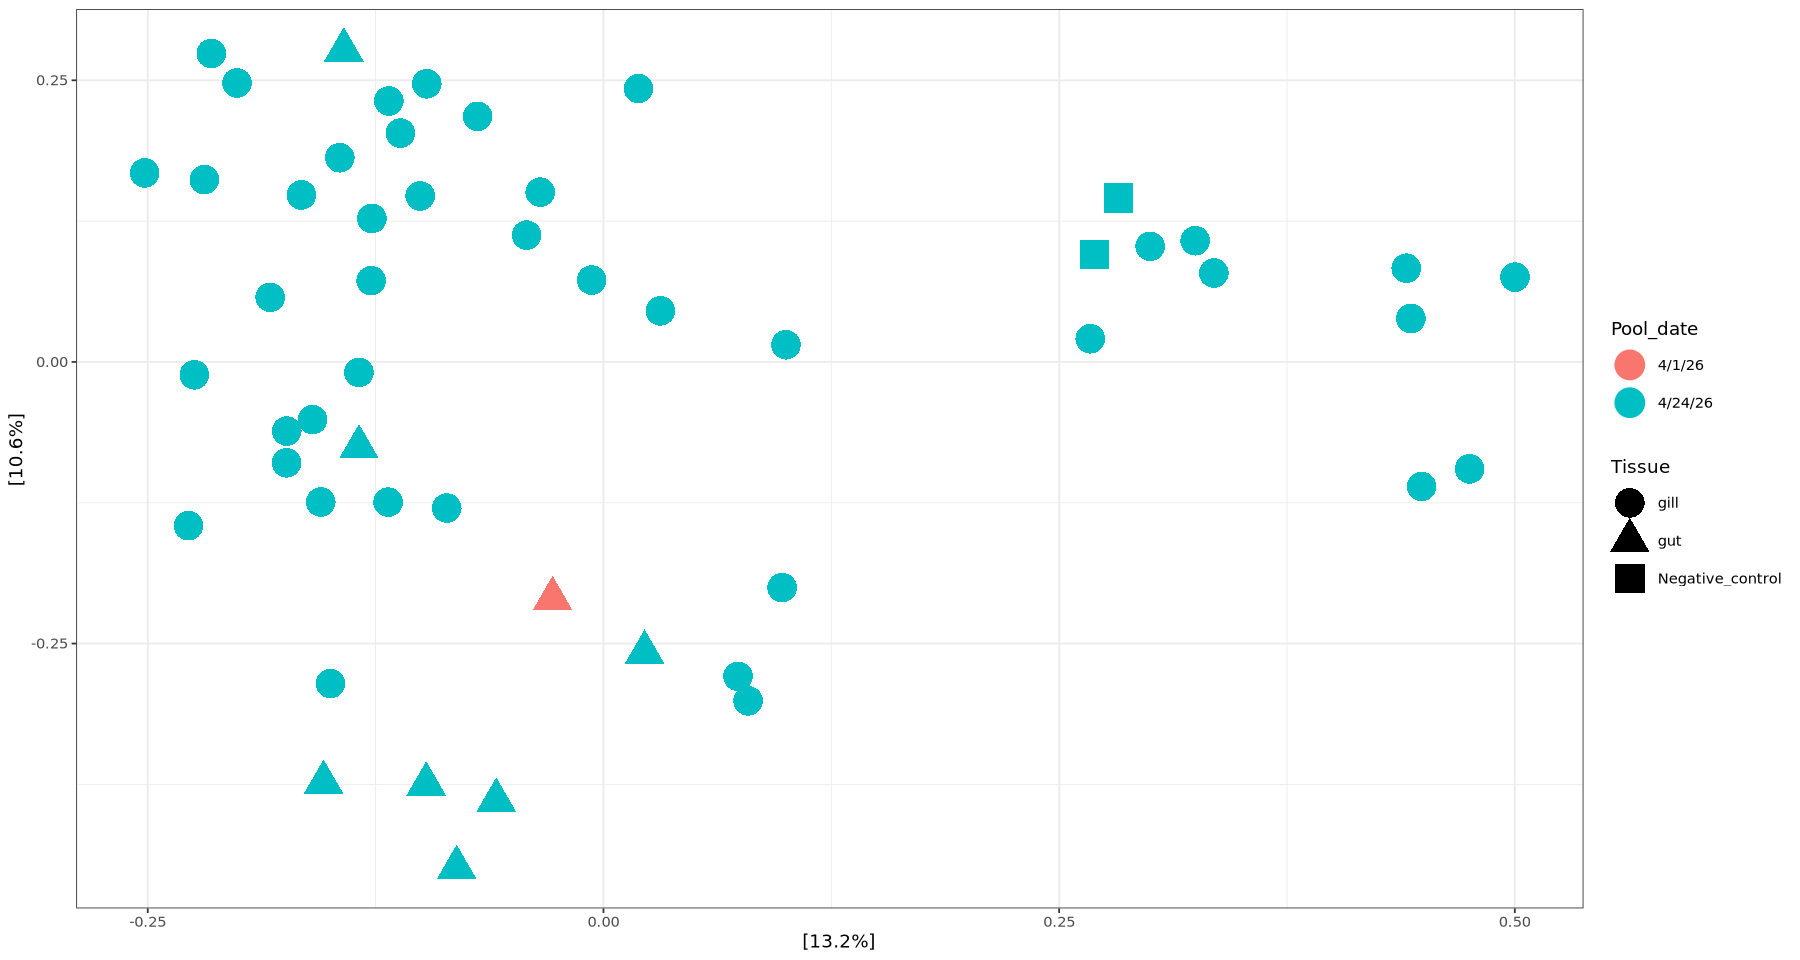

In [54]:
plot_ordination(ps_july6, july6.ord, color = "Pool_date", shape = "Tissue") +
    geom_point(size=8) +
    theme_bw()

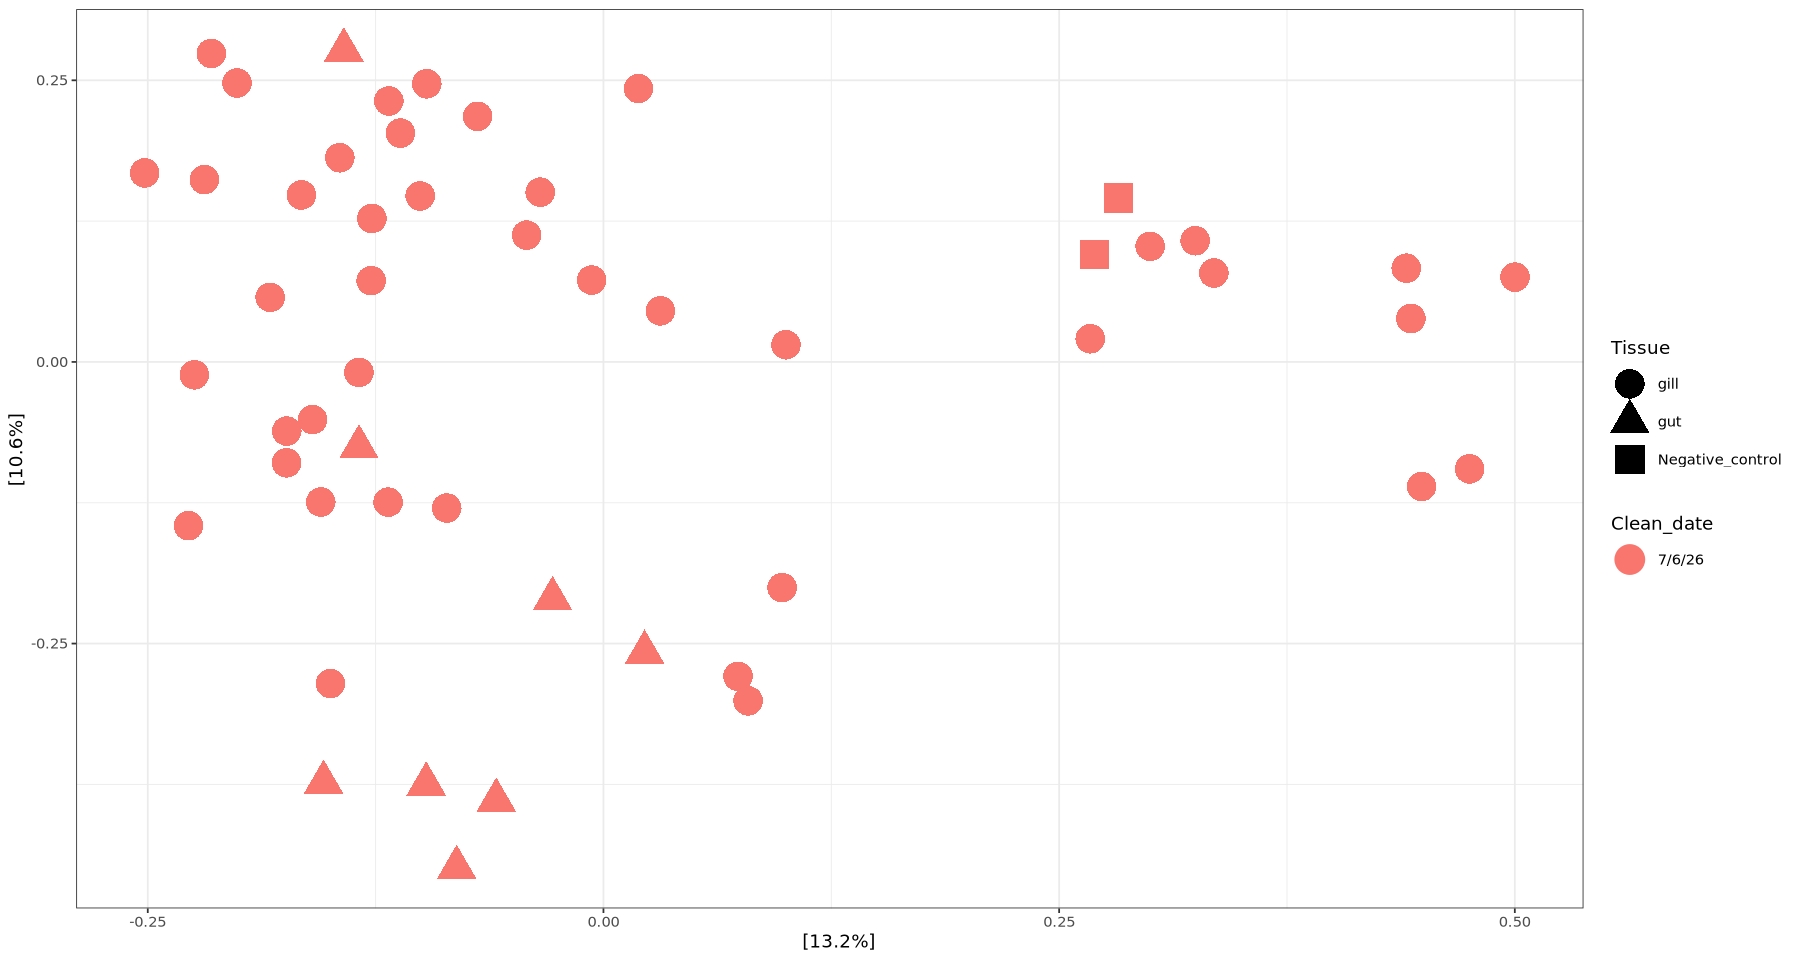

In [55]:
plot_ordination(ps_july6, july6.ord, color = "Clean_date", shape = "Tissue") +
    geom_point(size=8) +
    theme_bw()

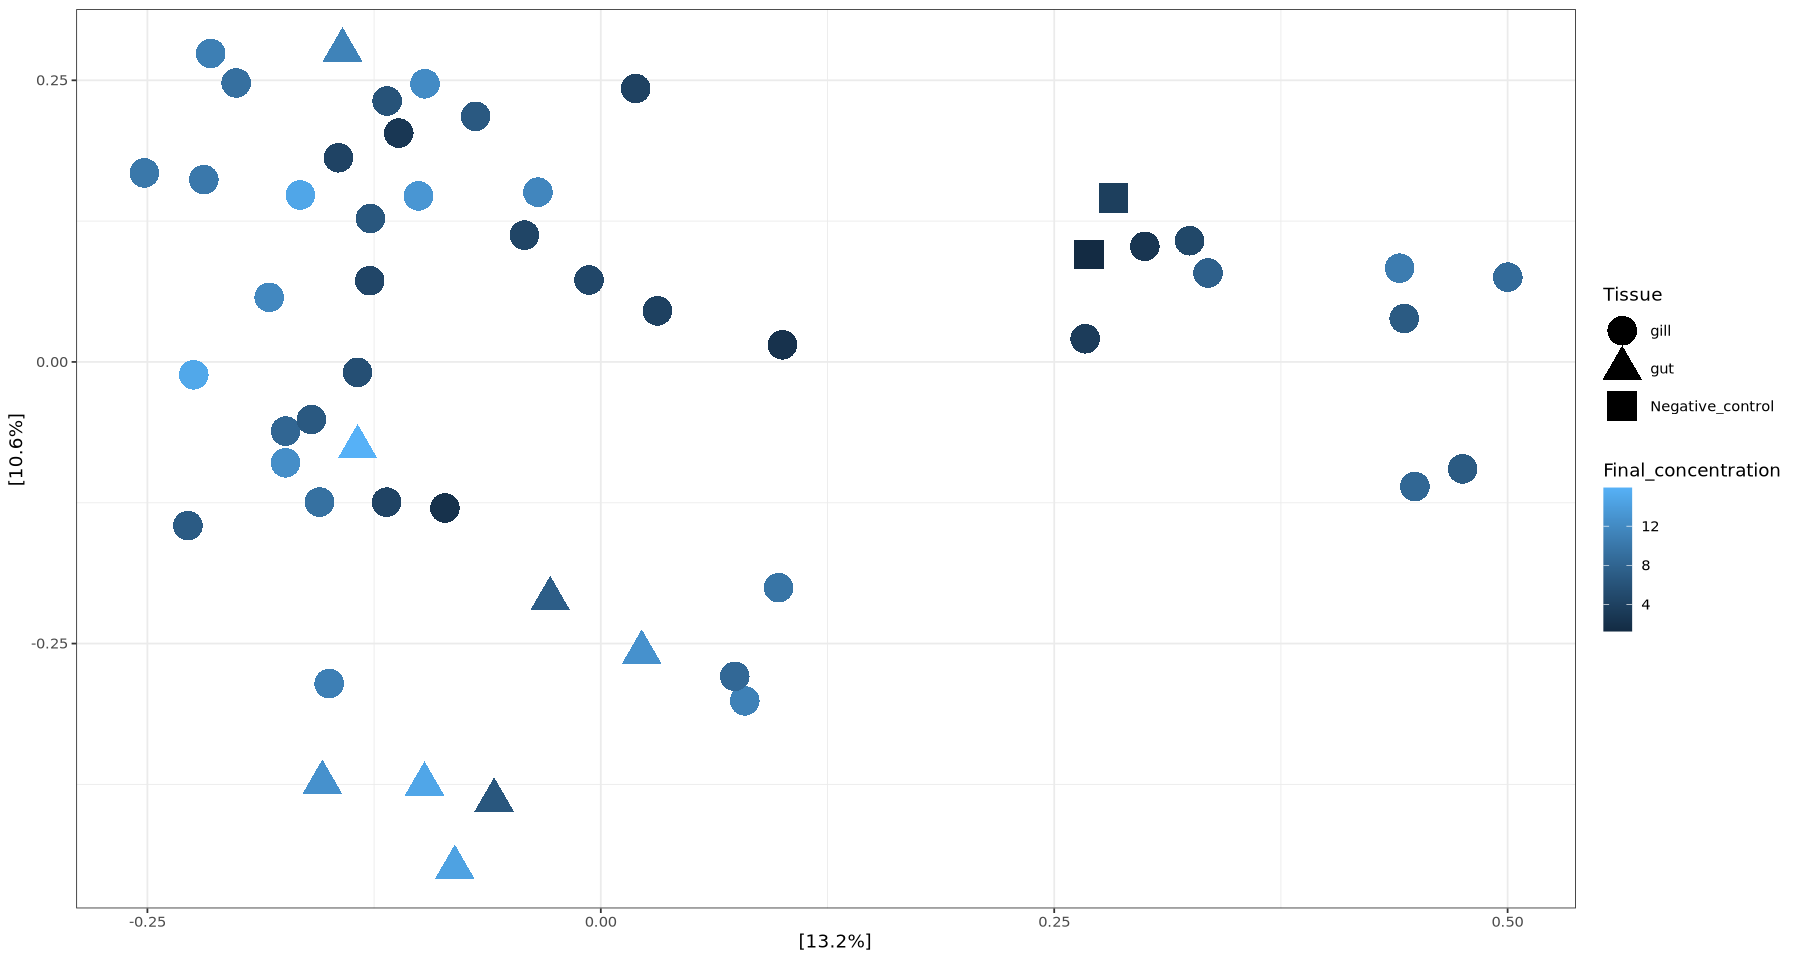

In [56]:
plot_ordination(ps_july6, july6.ord, color = "Final_concentration", shape = "Tissue") +
    geom_point(size=8) +
    theme_bw()

## 10.29.26 | compare different taxonomic assignments

### Create phyloseq ojbect using DADA2 taxonomy

In [1]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(tidyverse)
})

In [2]:
# Read ASV table
asvTable <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ASV_nochim_2.rds")

# Read taxonomy table
taxaDADA2 <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/taxa_species.rds")

# Read tidied metadata
sampleMetadata <- read.csv("/project/pi_sarah_gignouxwolfsohn_uml_edu/jade/ORCC_16S/metadata/metadata_samples.csv", row.names=1)

In [ ]:
# Check that row names are identical
head(asvTable)
head(sampleMetadata)

In [ ]:
# Rearrange metadata sample order to match ASV table sample order
sampleMetadata <- sampleMetadata[match(rownames(asvTable), rownames(sampleMetadata)), ]
head(asvTable)
head(sampleMetadata)

In [5]:
# Create phyloseq object
psD <- phyloseq(otu_table(asvTable, taxa_are_rows = FALSE),
                     sample_data(sampleMetadata),
                     tax_table(taxaDADA2))
psD 

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 145375 taxa and 281 samples ]
sample_data() Sample Data:       [ 281 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 145375 taxa by 7 taxonomic ranks ]

In [31]:
# Extract ASV sequences
dna <- Biostrings::DNAStringSet(taxa_names(psD))
names(dna) <- taxa_names(psD)

# Create reference sequence component of phyloseq object to store the raw ASVs
psD <- merge_phyloseq(psD, dna)

# Rename ASVs numerically
taxa_names(psD) <- paste0("ASV", seq(ntaxa(psD)))
psD

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 145375 taxa and 281 samples ]
sample_data() Sample Data:       [ 281 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 145375 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 145375 reference sequences ]

In [32]:
# Compare to decipher phyloseq object
ps <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps.rds")
ps

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 145375 taxa and 281 samples ]
sample_data() Sample Data:       [ 281 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 145375 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 145375 reference sequences ]

### Clean DADA2 phyloseq object

In [37]:
# Remove samples with less than 10k reads
psD_10k <- prune_samples(sample_sums(ps) >= 10000, psD)

# Compare phyloseq objects
psD
psD_10k

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 145375 taxa and 281 samples ]
sample_data() Sample Data:       [ 281 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 145375 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 145375 reference sequences ]

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 145375 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 145375 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 145375 reference sequences ]

In [36]:
# Explore which samples were lost
low_samples <- sample_sums(ps) < 10000
sample_names(ps)[low_samples]

[1] "2024_Both01_Null_O03_gill"   "2024_Both04_Null_O32_gill"  
[3] "2024_Both05_Both06_O69_gill" "2024_Cont03_Null_W21_gill"  
[5] "2024_Cont04_Cont06_W67_gill" "2024_Warm01_Hyp05_G49_gill" 
[7] "Pooled_negative_rack3_2_NA"

In [38]:
# Keep just bacteria
psD_bacteria <- subset_taxa(psD_10k, Kingdom == "Bacteria")
psD_bacteria

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 139132 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 139132 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 139132 reference sequences ]

In [39]:
# Remove taxa that are no longer represented in phyloseq object
psD_prune <- prune_taxa(taxa_sums(psD_bacteria) > 0, psD_bacteria)
psD_prune

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 137370 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 137370 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 137370 reference sequences ]

In [40]:
# Convert raw counts to relative abundance counts per million
psD_norm = transform_sample_counts(psD_prune, function(x) 1E6 * x / sum(x))

In [41]:
# Save phyloseq object
saveRDS(psD_norm, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/psD_norm.rds")

In [42]:
# Compare clean and normalized phyloseq objects
ps_norm <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps_norm.rds")
psD_norm
ps_norm

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 137370 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 137370 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 137370 reference sequences ]

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 66218 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 66218 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 66218 reference sequences ]

### PCoA plot comparisons

#### Raw reads

In [43]:
# Add label to negative controls in the tissue column of the sample_data df
sample_data(psD)$Tissue[grepl("negative", sample_names(psD))] <- "Negative_control"
sample_data(ps)$Tissue[grepl("negative", sample_names(ps))] <- "Negative_control"

In [44]:
# PCoA ordination of all samples
all.ord <- ordinate(ps, "PCoA", "bray")

In [45]:
all.ordD <- ordinate(psD, "PCoA", "bray")

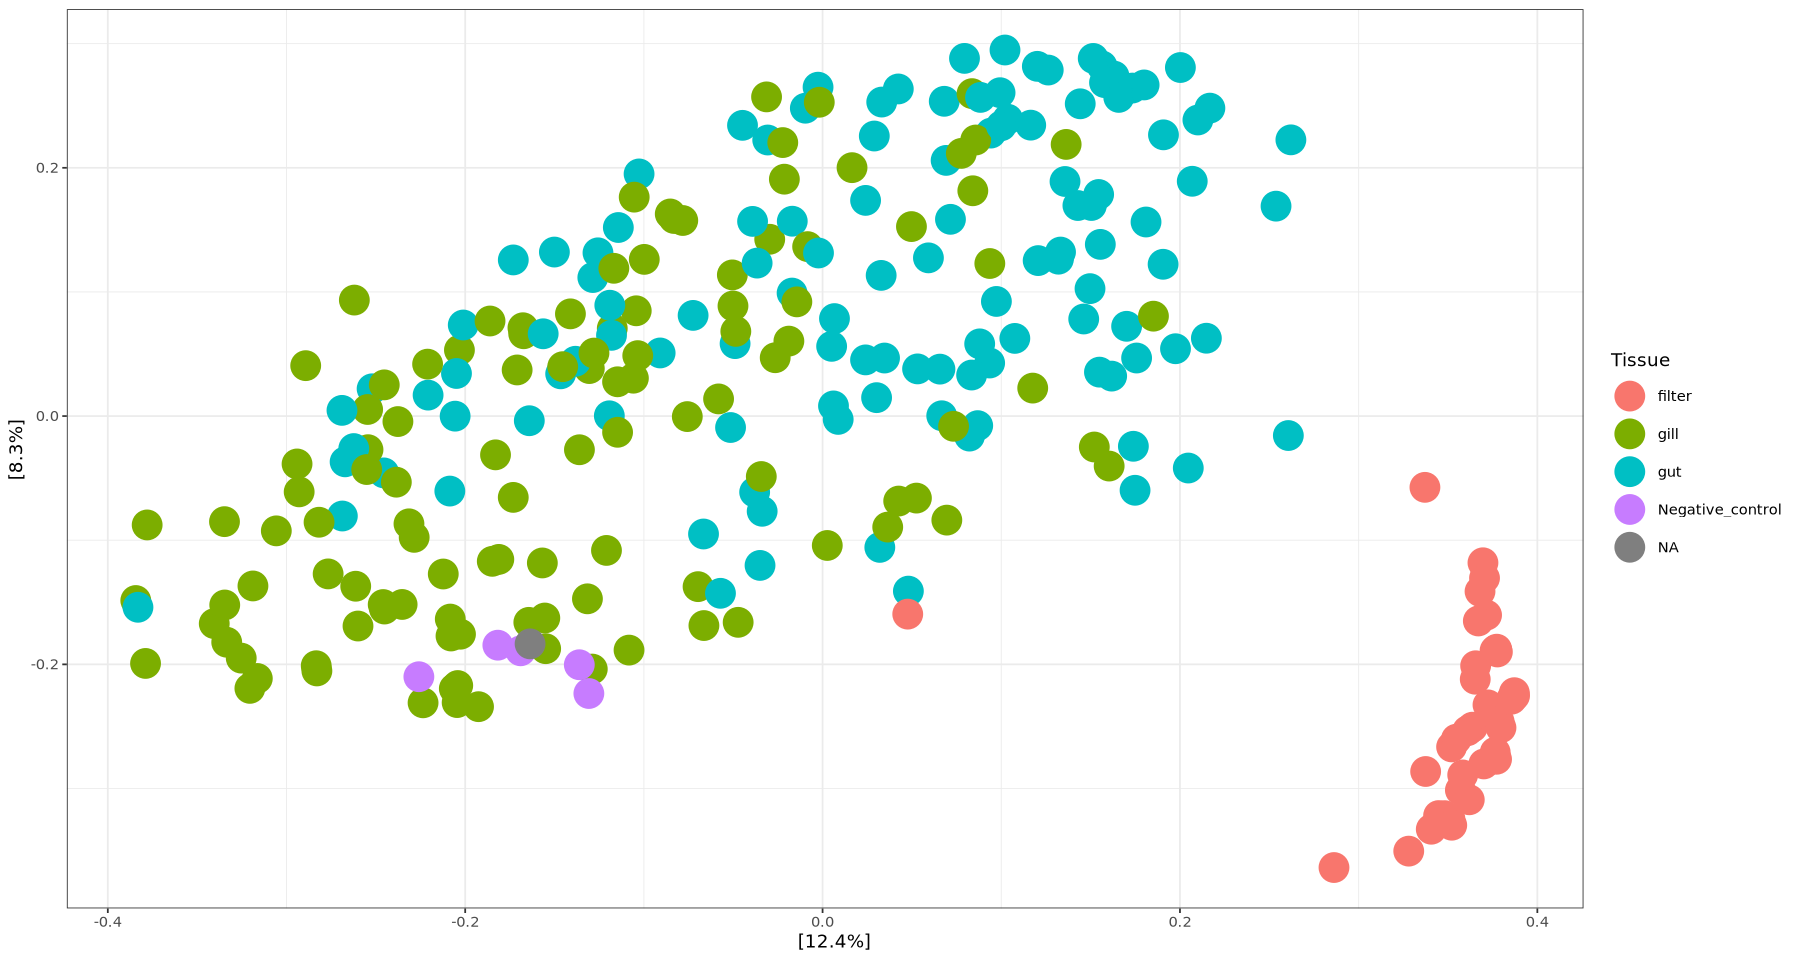

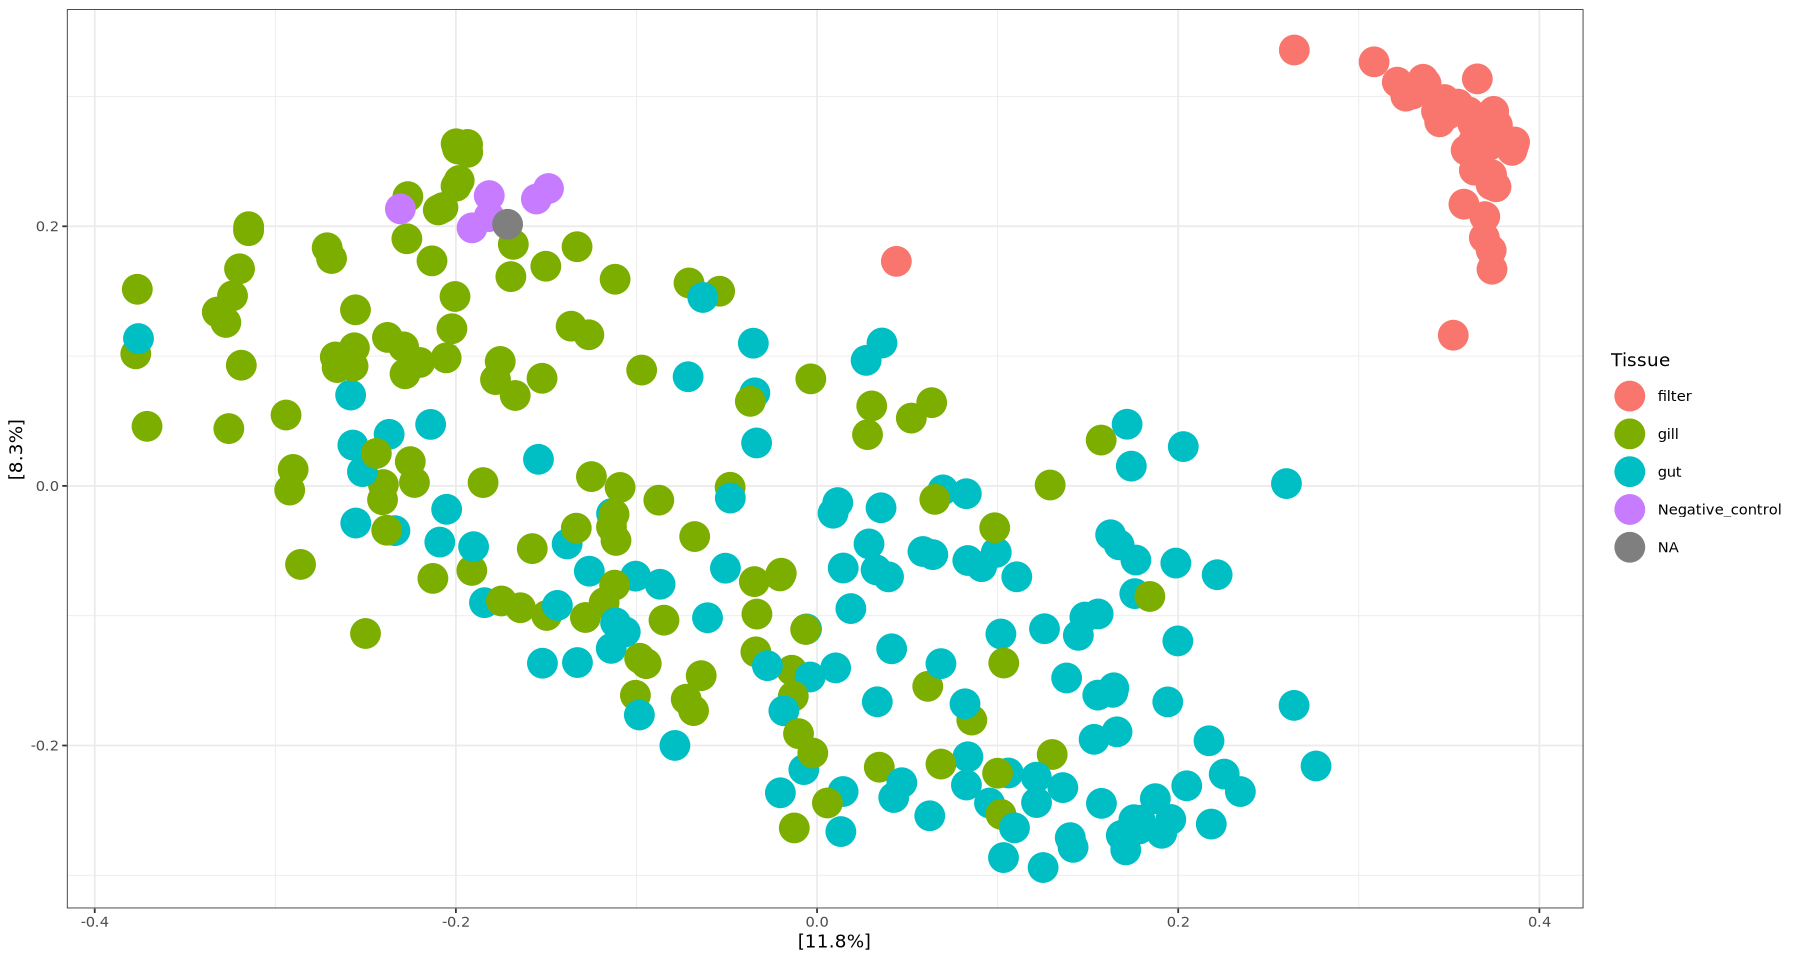

In [58]:
# Plot PCoA of all samples
plot_ordination(psD, all.ordD, color = "Tissue") +
    geom_point(size=8) +
    labs(title="DADA2, raw") +
    theme_bw()
# Plot PCoA of all samples
plot_ordination(ps, all.ord, color = "Tissue") +
    geom_point(size=8) +
    labs(title="DECIPHER, raw") +
    theme_bw()

#### Pruned reads

In [63]:
# Add label to negative controls in the tissue column of the sample_data df
sample_data(psD_prune)$Tissue[grepl("negative", sample_names(psD_prune))] <- "Negative_control"
sample_data(ps_prune)$Tissue[grepl("negative", sample_names(ps_prune))] <- "Negative_control"

In [64]:
# PCoA ordination of all samples
all.ordD_prune <- ordinate(psD_prune, "PCoA", "bray")
all.ord_prune <- ordinate(ps_prune, "PCoA", "bray")

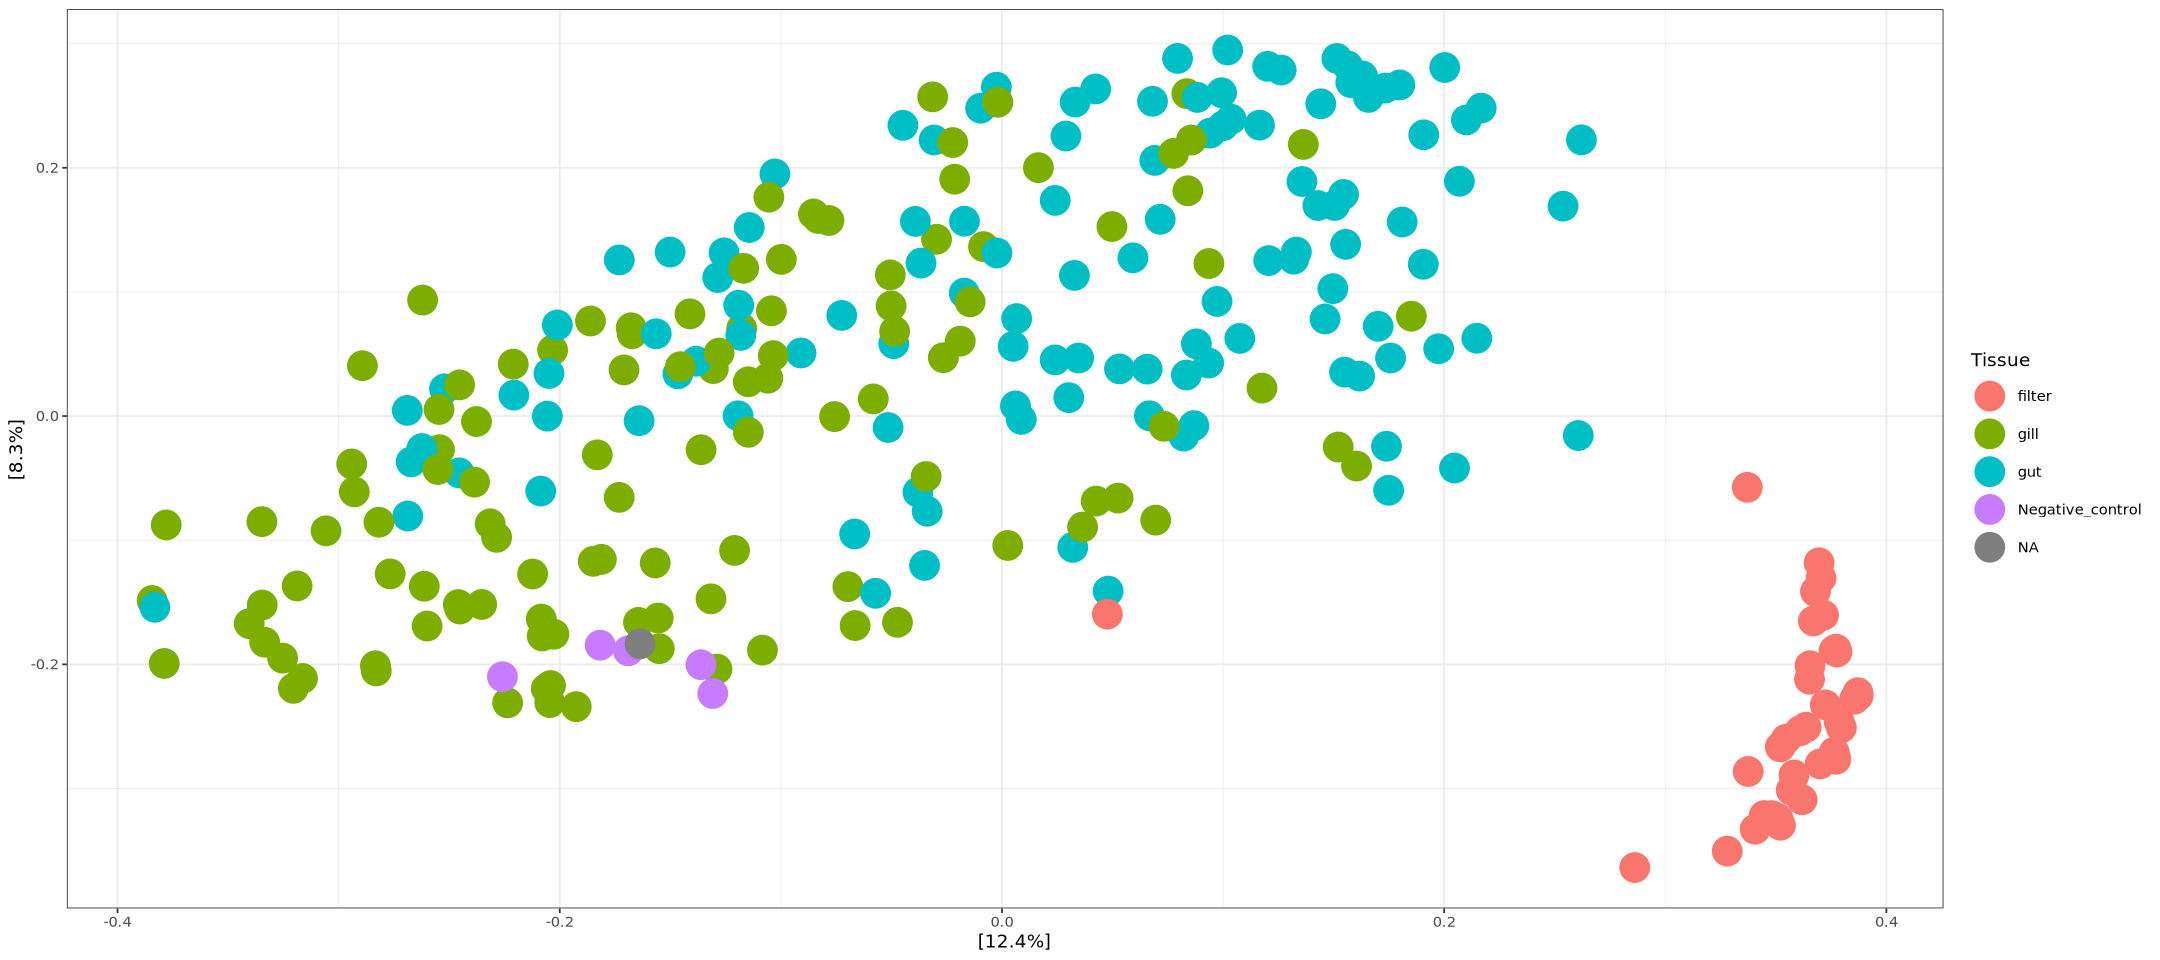

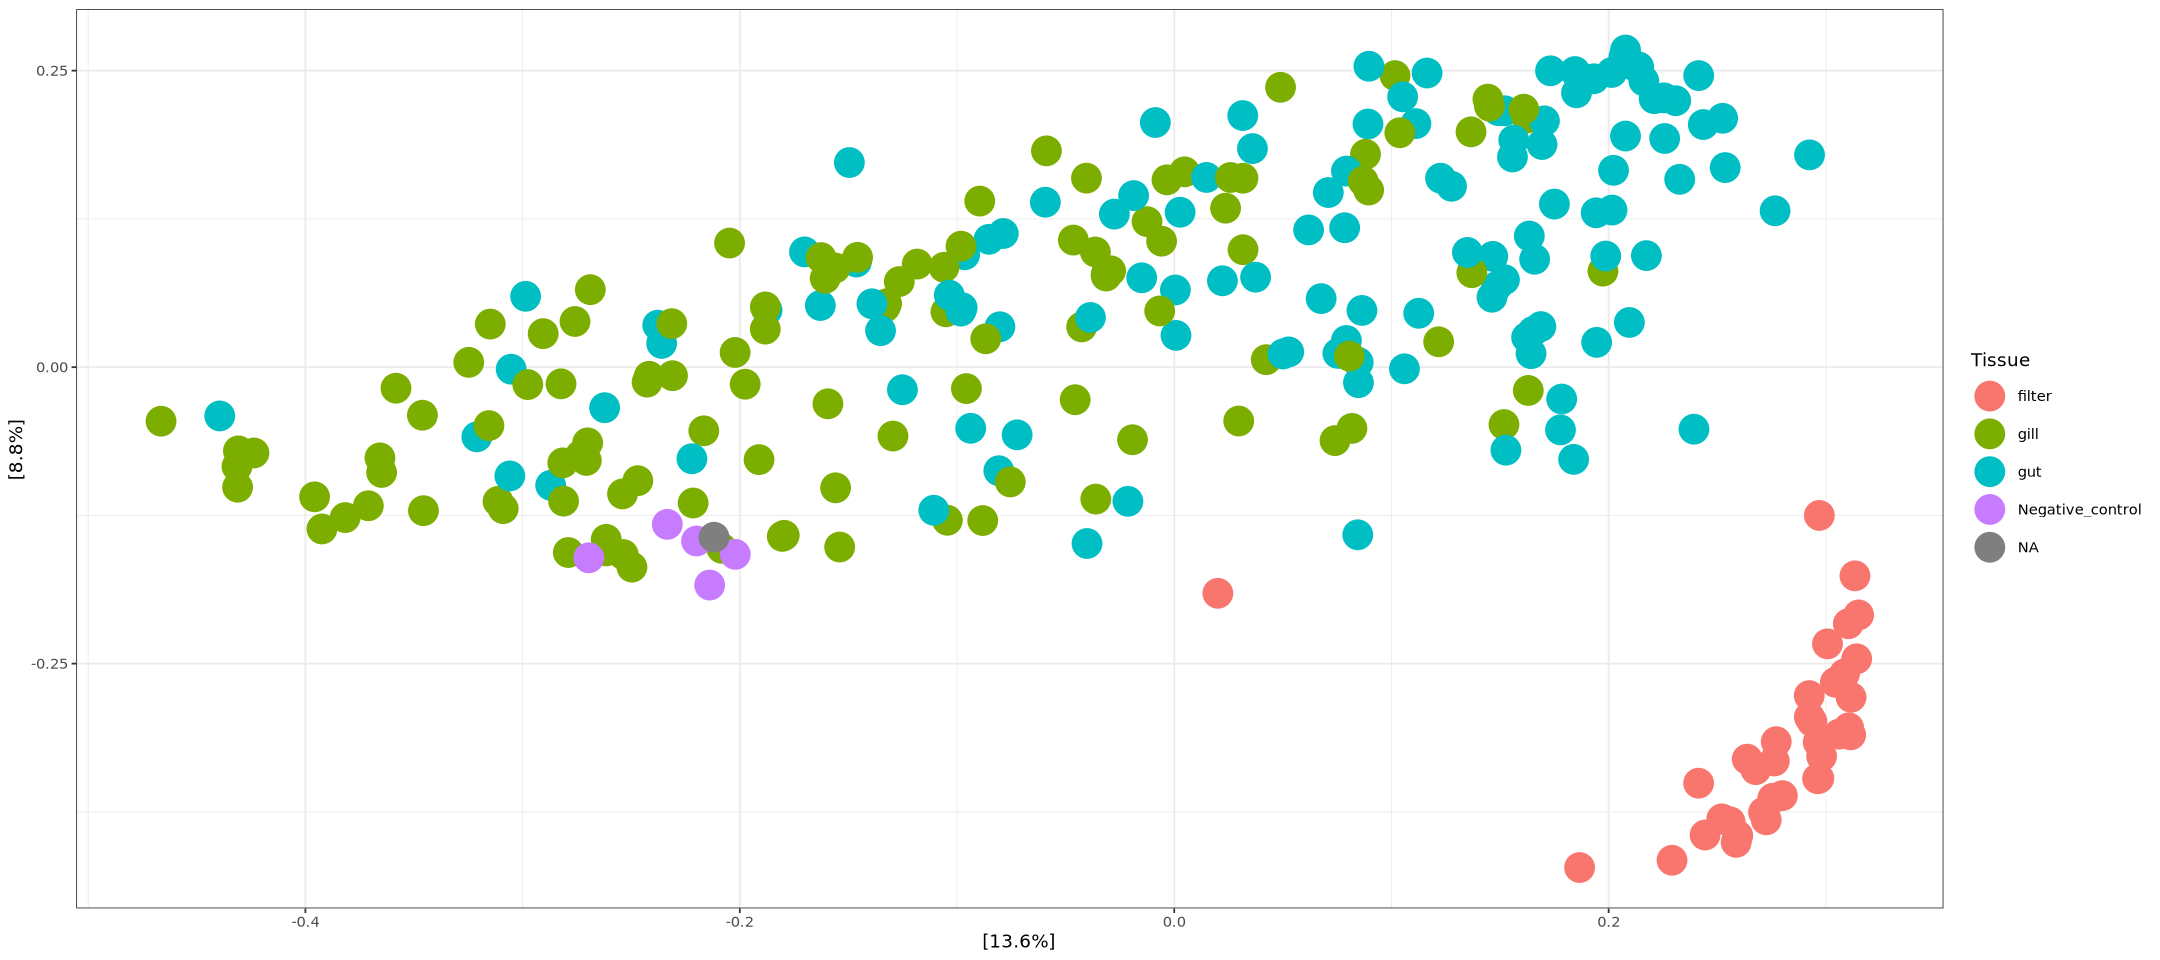

In [65]:
# Plot PCoA of all samples
plot_ordination(psD_prune, all.ordD_prune, color = "Tissue") +
    geom_point(size=8) +
    labs(title="DADA2, pruned") +
    theme_bw()
# Plot PCoA of all samples
plot_ordination(ps_prune, all.ord_prune, color = "Tissue") +
    geom_point(size=8) +
    labs(title="DECIPHER, pruned") +
    theme_bw()

#### Pruned phase 2 reads, only dada2

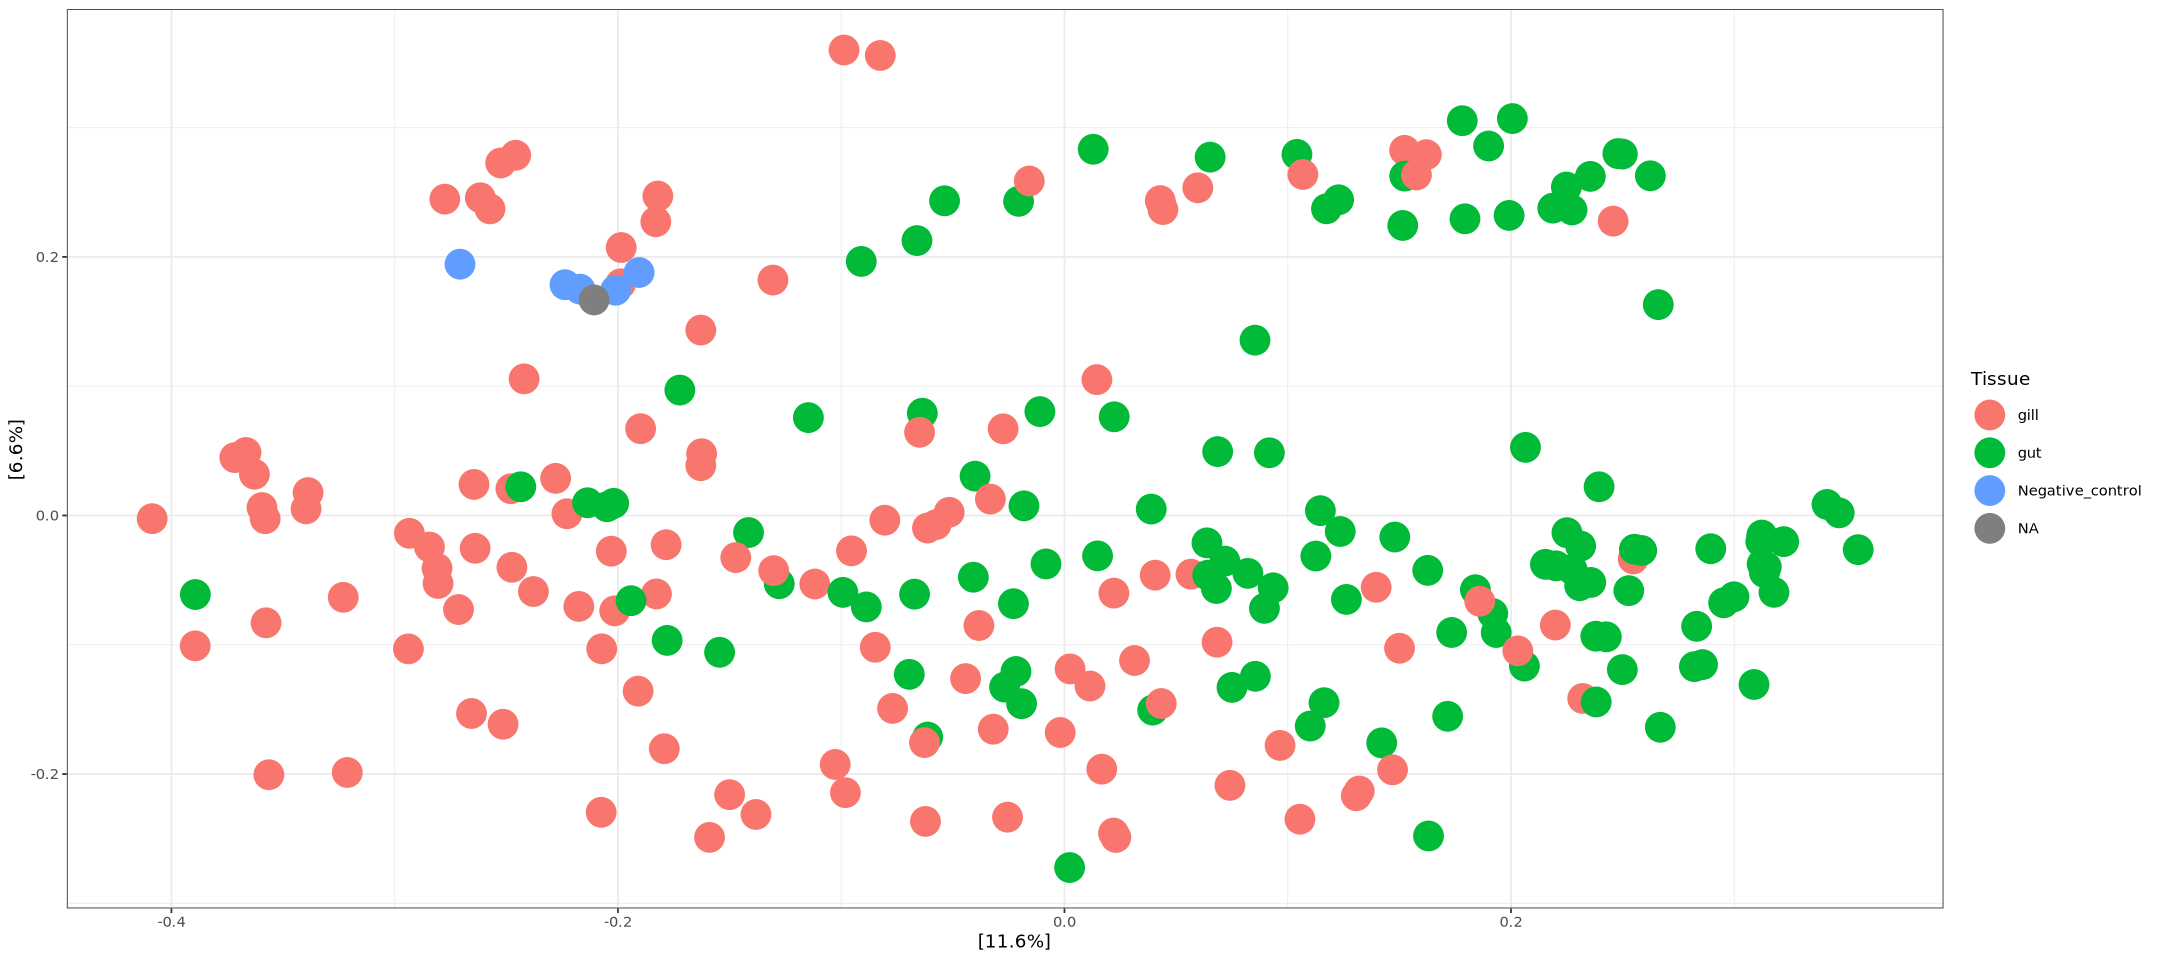

In [67]:
# Remove filter samples from PCoA and plot
psD_tissue_prune <- subset_samples(psD_prune, is.na(Tissue) | Tissue != "filter")
tissue.ordD_prune <- ordinate(psD_tissue_prune, "PCoA", "bray")
plot_ordination(psD_tissue_prune, tissue.ordD_prune, color = "Tissue") +
    geom_point(size=8) +
    theme_bw()

In [69]:
# Label negative controls as phase 2 in the sample_data df
sample_data(psD_tissue_prune)$Phase[grepl("negative", sample_names(psD_tissue_prune))] <- "2"
sample_data(psD_tissue_prune)$Phase[grepl("Positive", sample_names(psD_tissue_prune))] <- "2"
sample_data(psD_tissue_prune)$Tissue[grepl("Positive", sample_names(psD_tissue_prune))] <- "Positive_control"

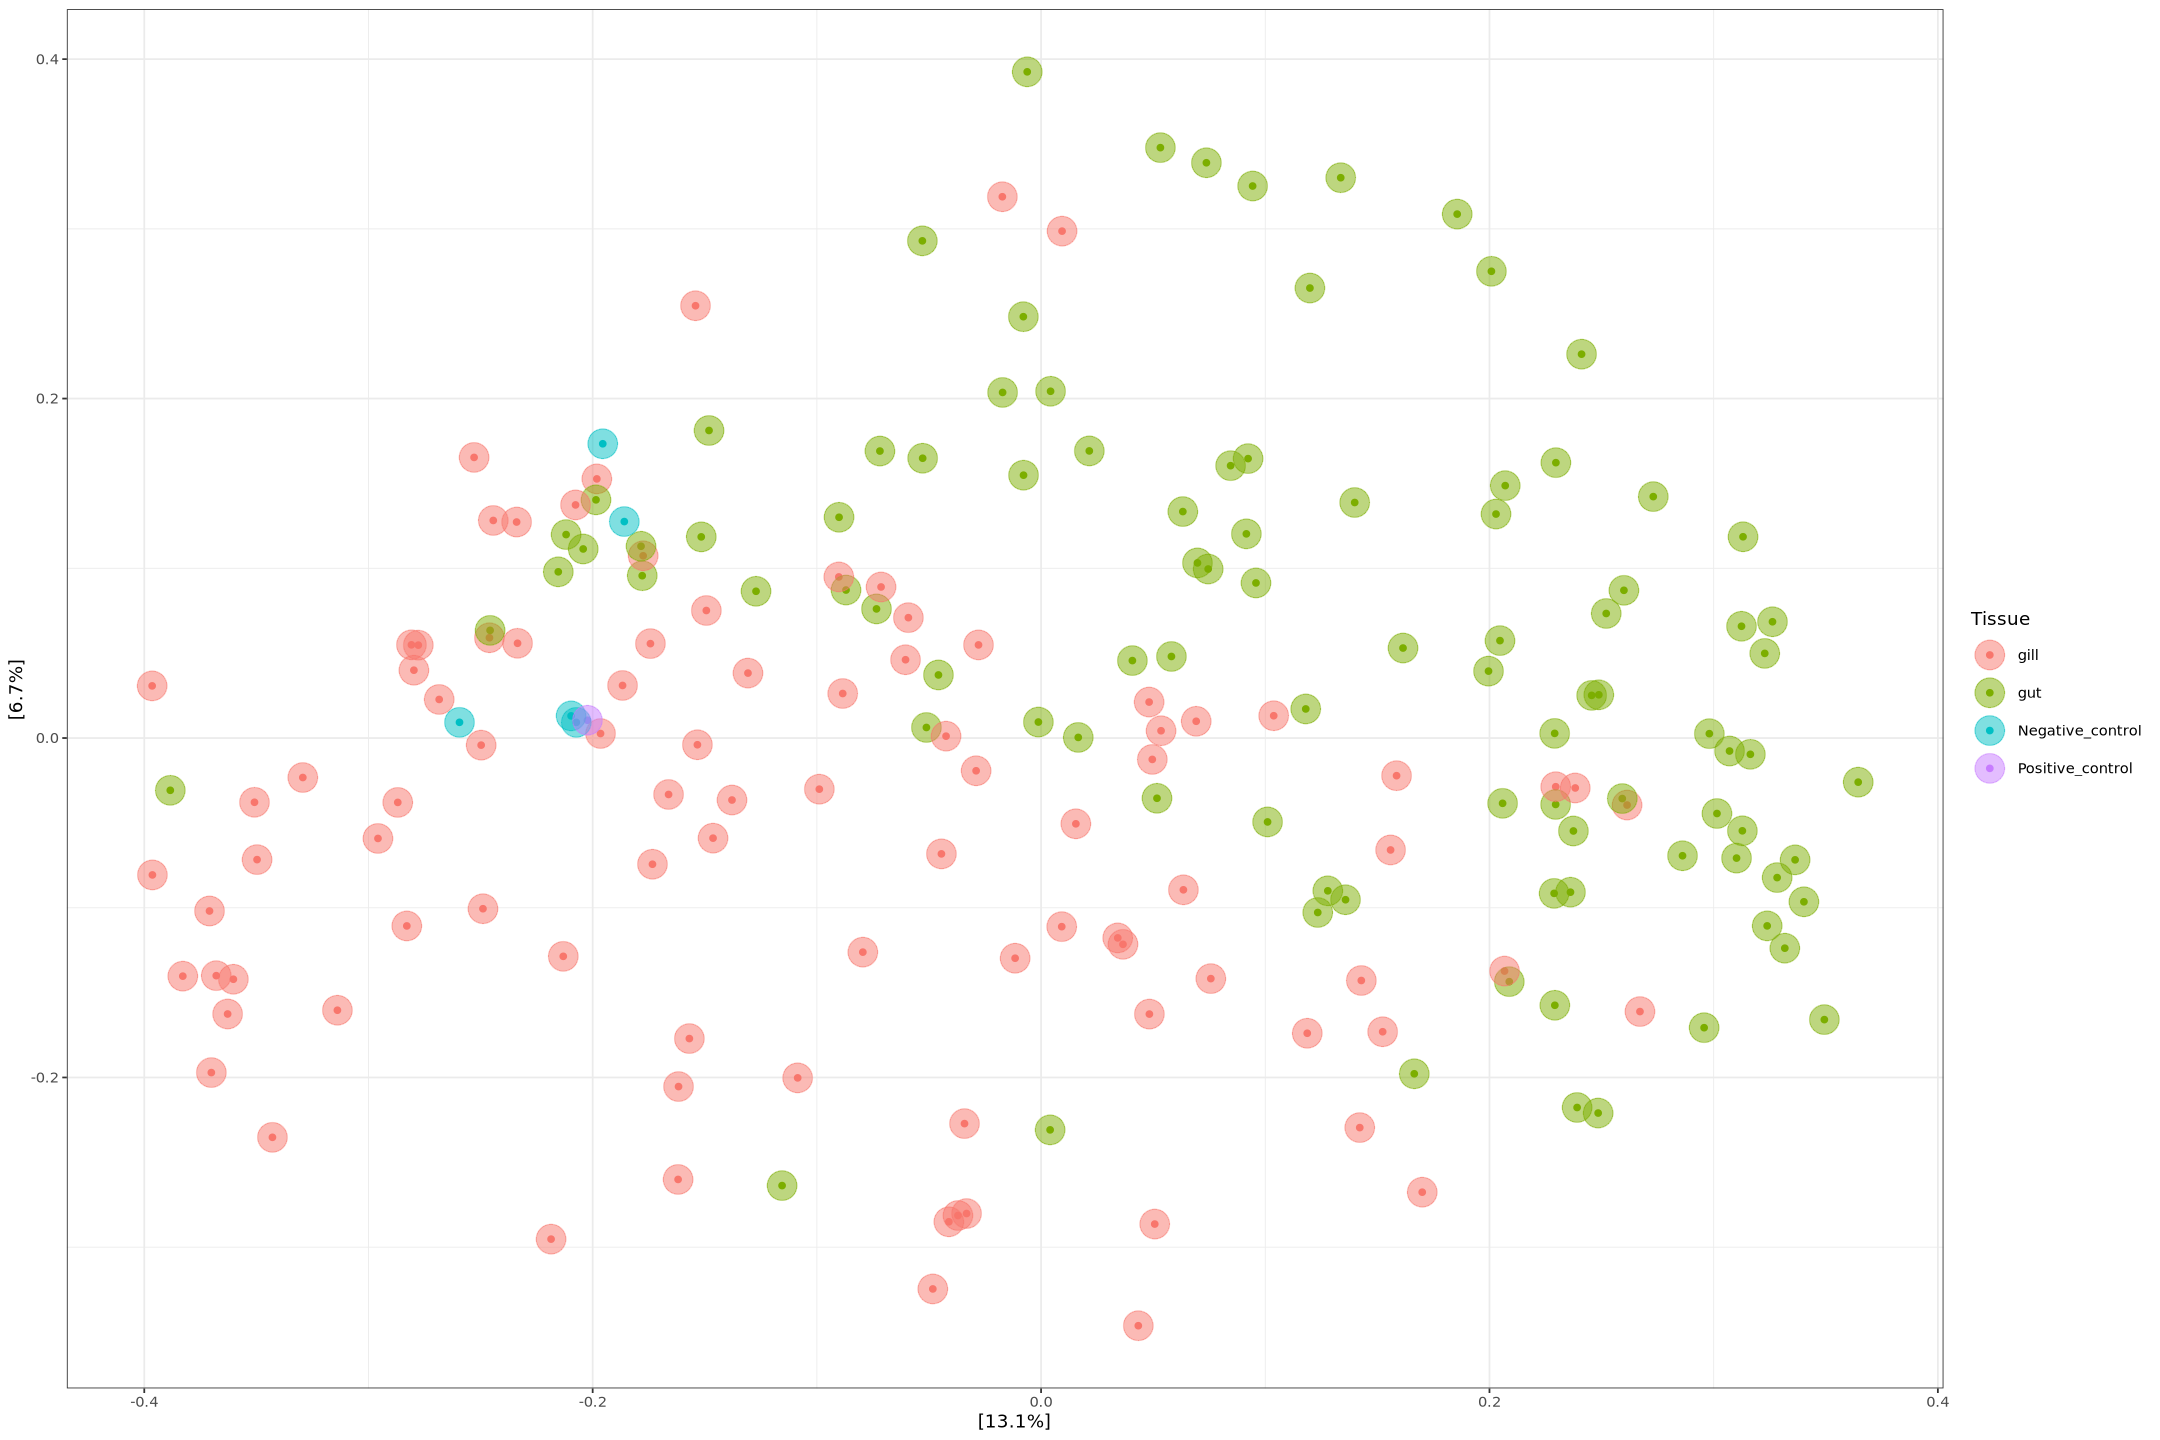

In [71]:
# Subset and oordinate Phase 1 samples 
options(repr.plot.width=18, repr.plot.height=12)
psD_p2 <- subset_samples(psD_tissue_prune, Phase == 2)
p2.ordD <- ordinate(psD_p2, "PCoA", "bray")
plot_ordination(psD_p2, p2.ordD, color = "Tissue") +
    geom_point(size=8, alpha=0.5) +
    theme_bw()

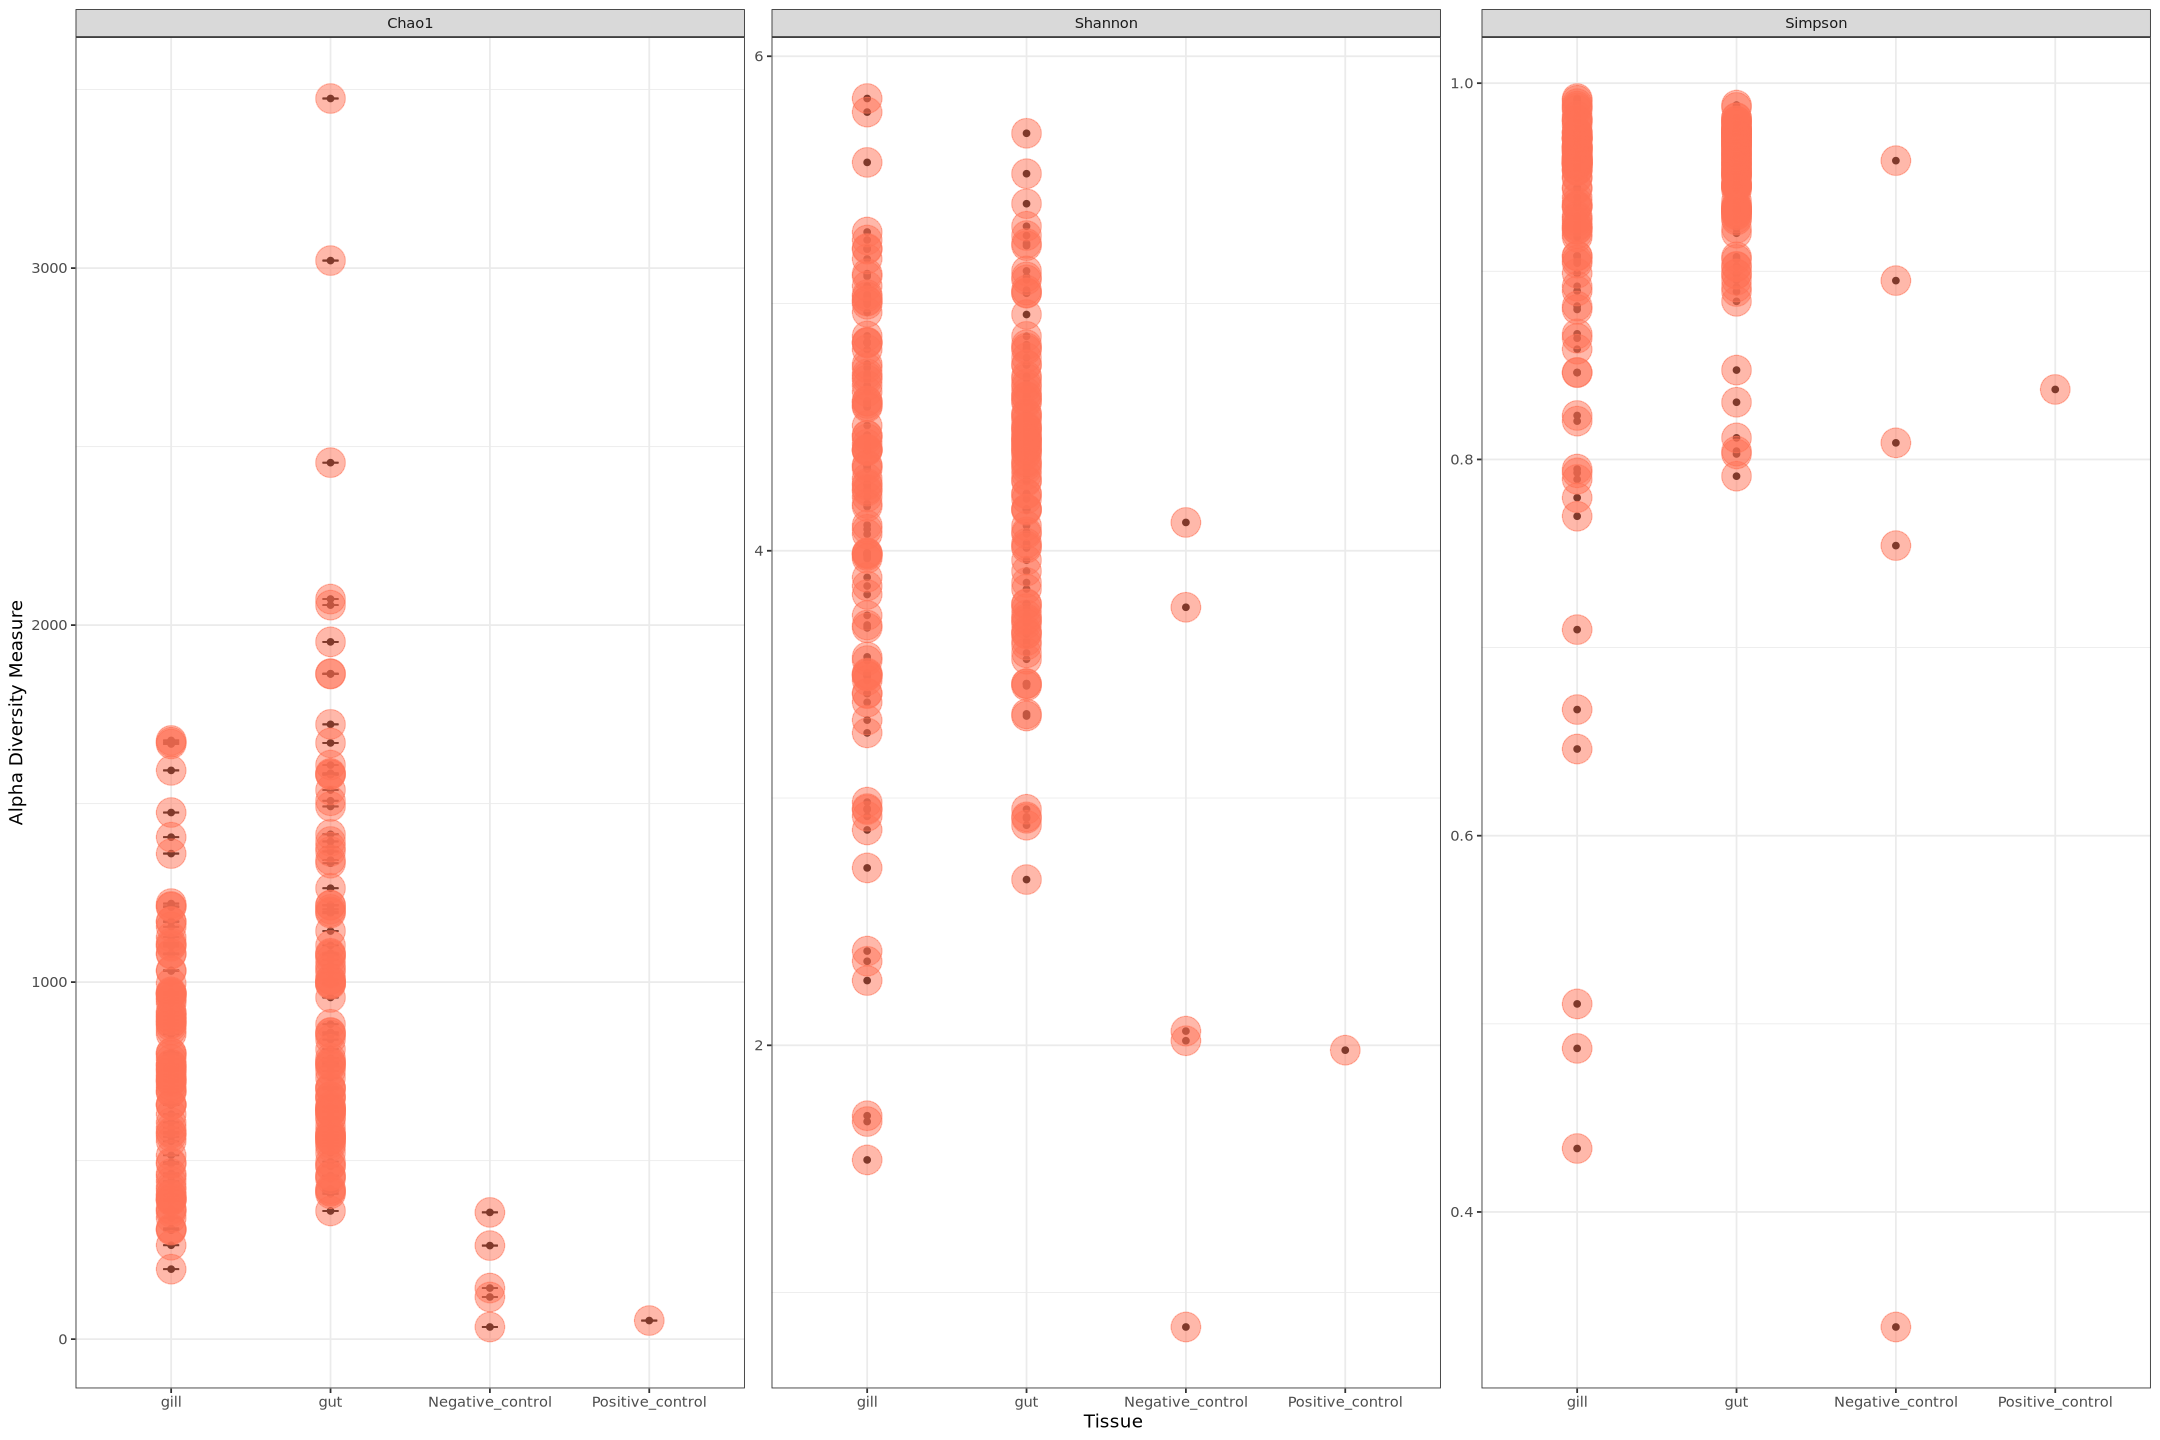

In [72]:
# Plot alpha diversity metrics
plot_richness(psD_p2, x = "Tissue", measures = c("Shannon", "Simpson", "Chao1")) +
    geom_point(size = 8, alpha = 0.5, color = "coral 1")  +
    theme_bw()

In [73]:
psD_p2

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 137370 taxa and 193 samples ]
sample_data() Sample Data:       [ 193 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 137370 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 137370 reference sequences ]

In [75]:
# Read in phyloseq object with just phase 2 samples - decipher taxonomic assignmnet
ps_p2 <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps_p2.rds")

In [76]:
ps_p2

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 145375 taxa and 197 samples ]
sample_data() Sample Data:       [ 197 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 145375 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 145375 reference sequences ]